# Notebook 3A.02: Comparação de modelos com Gradient Boosting

## MLP x XGBoost na estimação horária de CO₂

Este notebook dá continuidade aos experimentos realizados nos Notebooks **3A** e **3A.01**.

No Notebook 3A, a inclusão de informações sobre memória e trajetória operacional melhorou a estimação horária de CO₂ em relação ao uso exclusivo da carga instantânea.

Foram avaliados:

**Cenário A: carga instantânea**

`CO₂(t) = f(P(t))`

**Cenário B: trajetória operacional básica**

O Cenário B apresentou melhora global em relação ao Cenário A.

No Notebook 3A.01 foi criado:

**Cenário C: trajetória temporal enriquecida**

O objetivo era verificar se uma representação temporal mais detalhada permitiria melhorar ainda mais o desempenho da MLP.

Entretanto, o Cenário C não apresentou melhora global consistente em relação ao Cenário B.

Os principais resultados foram:

- MAE de B: aproximadamente 61,61 short tons;
- MAE de C: aproximadamente 62,65 short tons;
- RMSE praticamente equivalente;
- R² praticamente equivalente;
- Cenário C melhor que B em apenas 42,9% das horas;
- melhora relevante durante startups;
- pequena melhora durante rampas intensas.

## Diagnóstico

Os resultados sugerem que as novas features contêm informação operacional relevante, principalmente em regimes transitórios, mas a MLP utilizada pode não estar explorando adequadamente essa estrutura adicional.

Esse resultado motiva a avaliação de uma família de modelos diferente.

## Hipótese desta etapa

> **Modelos de Gradient Boosting conseguem explorar melhor as relações não lineares entre as variáveis operacionais e as emissões horárias de CO₂ do que a MLP utilizada nos experimentos anteriores?**

## Estratégia

Será utilizado o **XGBoost Regressor**, modelo baseado em árvores de decisão construídas sequencialmente.

Serão avaliados novamente:

### Cenário B

As mesmas 7 features de trajetória básica utilizadas no Notebook 3A.

### Cenário C

As mesmas 24 features utilizadas no Notebook 3A.01.

Nenhuma nova feature será adicionada nesta etapa.

Assim, a comparação permite separar dois efeitos:

1. efeito da quantidade e qualidade das informações fornecidas ao modelo;
2. efeito da família de algoritmo utilizada para aprender essas relações.

## Validação temporal progressiva

Antes da comparação com novembro e dezembro, os modelos serão avaliados por validação temporal progressiva dentro do período de desenvolvimento.

Serão utilizados cinco folds:

| Fold | Treino | Validação |
|---|---|---|
| 1 | janeiro a maio | junho |
| 2 | janeiro a junho | julho |
| 3 | janeiro a julho | agosto |
| 4 | janeiro a agosto | setembro |
| 5 | janeiro a setembro | outubro |

Essa estratégia permite verificar se o desempenho é consistente ao longo do tempo e reduz a dependência de um único mês de validação.

## Avaliação histórica final

Para manter comparabilidade com os notebooks anteriores, serão treinados modelos finais utilizando:

- treino: janeiro a setembro;
- validação: outubro;
- avaliação histórica: novembro e dezembro.

Entretanto, novembro e dezembro já foram observados nos experimentos anteriores.

Portanto, esse período será utilizado como **holdout histórico de comparação**, e não como teste completamente cego para novas decisões de desenvolvimento.

## Métricas

Serão analisados:

- MAE;
- RMSE;
- R²;
- viés médio;
- desempenho em startups;
- desempenho em rampas intensas;
- estabilidade entre folds temporais;
- importância das features no XGBoost.

## Controle experimental

Nesta etapa não será realizada busca de hiperparâmetros.

Será utilizada uma configuração fixa e conservadora do XGBoost.

O objetivo é primeiro verificar se a mudança de família de modelo apresenta benefício suficiente para justificar uma etapa posterior de otimização.

## Fundamentação, fontes e decisões do protocolo

As notas metodológicas vinculam as técnicas empregadas às respectivas publicações ou documentações oficiais. As referências completas aparecem ao final deste notebook. As rotinas de leitura, persistência, verificação de integridade e organização dos resultados são implementações do projeto.

**Escolhas do estudo.** Os cenários A, B e C, o calendário dos cinco folds, os hiperparâmetros e as condições de reajuste são definidos pelo protocolo. As MLPs usadas como referência e os modelos XGBoost possuem procedimentos de seleção próprios, que precisam ser considerados ao interpretar a comparação.

**Atualização documental de 24/10/2026.** Foram acrescentadas explicações, citações e referências. As instruções executáveis e as saídas armazenadas foram preservadas. Esta revisão não corresponde a uma nova execução dos experimentos. A rastreabilidade da verificação computacional permanece nos registros de reprodução.

O [guia de fundamentação metodológica](../docs/fundamentacao_metodologica.md) relaciona as fontes, seu alcance e os controles adotados ao longo dos notebooks.


In [1]:
# ============================================================
# CÉLULA 1: CONFIGURAÇÃO DO AMBIENTE
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Preparar o ambiente utilizado no Notebook 3A.02.
#
# Nesta célula:
#
#   1. importamos bibliotecas gerais;
#   2. importamos o XGBoost;
#   3. configuramos reprodutibilidade;
#   4. montamos o Google Drive;
#   5. definimos os diretórios do projeto;
#   6. localizamos os dados e resultados anteriores.
#
# Nenhum modelo é treinado nesta etapa.
# ============================================================


# ============================================================
# 1. IMPORTAÇÕES GERAIS
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import xgboost as xgb

from xgboost import XGBRegressor

from IPython.display import (
    display,
    Markdown
)


# ============================================================
# 2. CONFIGURAÇÕES GERAIS
# ============================================================

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)

np.random.seed(SEED)


# ============================================================
# 3. VERSÃO DO XGBOOST
# ============================================================
#
# Registrar a versão é importante para reprodutibilidade.
# ============================================================

print(
    "XGBoost:",
    xgb.__version__
)


# ============================================================
# 4. GOOGLE DRIVE
# ============================================================

drive.mount(
    "/content/drive"
)


# ============================================================
# 5. DIRETÓRIO PRINCIPAL
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/co2-cems-thermal-modeling"
)


DATA_INTERIM = (
    ROOT
    /
    "data"
    /
    "interim"
)


PIPELINE_DIR = (
    ROOT
    /
    "pipeline"
)


OUTPUT = (
    ROOT
    /
    "outputs"
)


REPORTS = (
    OUTPUT
    /
    "reports"
)


FIGURES = (
    OUTPUT
    /
    "figures"
)


TABLES = (
    OUTPUT
    /
    "tables"
)


MODELS = (
    OUTPUT
    /
    "models"
)


# ============================================================
# 6. GARANTIR AS PASTAS DE SAÍDA
# ============================================================

for folder in [

    REPORTS,
    FIGURES,
    TABLES,
    MODELS

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 7. ARQUIVOS DE ENTRADA
# ============================================================


# Unidade selecionada.

CONFIG_PATH = (
    PIPELINE_DIR
    /
    "selected_unit.json"
)


# Série horária completa.

FULL_DATA_PATH = (
    DATA_INTERIM
    /
    "step05_feature_engineering.parquet"
)


# ============================================================
# 8. RESULTADOS DOS EXPERIMENTOS ANTERIORES
# ============================================================


# Resultados A e B do Notebook 3A.

RESULTS_03A_PATH = (
    TABLES
    /
    "03A_comparacao_modelos.csv"
)


# Resultados A, B e C do Notebook 3A.01.

RESULTS_03A01_PATH = (
    TABLES
    /
    "03A01_comparacao_modelos.csv"
)


# Previsões produzidas no Notebook 3A.01.

PREDICTIONS_03A01_PATH = (
    TABLES
    /
    "03A01_previsoes_C.csv"
)


print("=" * 72)

print(
    "NOTEBOOK 3A.02: MLP x GRADIENT BOOSTING"
)

print("=" * 72)

print(
    "\nProjeto:"
)

print(
    ROOT
)

XGBoost: 3.4.1
Mounted at /content/drive
NOTEBOOK 3A.02: MLP x GRADIENT BOOSTING

Projeto:
/content/drive/MyDrive/co2-cems-thermal-modeling


In [2]:
# ============================================================
# CÉLULA 2: CARREGAMENTO DOS DADOS E DOS BASELINES
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Recuperar:
#
#   1. a unidade analisada;
#   2. a série horária completa;
#   3. os resultados dos modelos MLP anteriores;
#   4. as previsões anteriores utilizadas na comparação final.
#
# Os modelos antigos não serão treinados novamente.
# ============================================================


# ============================================================
# 1. VERIFICAR ARQUIVOS
# ============================================================

required_files = [

    CONFIG_PATH,

    FULL_DATA_PATH,

    RESULTS_03A_PATH,

    RESULTS_03A01_PATH,

    PREDICTIONS_03A01_PATH

]


for file_path in required_files:

    if not file_path.exists():

        raise FileNotFoundError(
            f"Arquivo não encontrado: {file_path}"
        )


# ============================================================
# 2. UNIDADE
# ============================================================

with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:

    selected_unit = json.load(f)


# ============================================================
# 3. SÉRIE HORÁRIA COMPLETA
# ============================================================

df = pd.read_parquet(
    FULL_DATA_PATH
)


df["timestamp"] = pd.to_datetime(
    df["timestamp"]
)


df = (

    df

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 4. RESULTADOS ANTERIORES
# ============================================================

results_03A = pd.read_csv(
    RESULTS_03A_PATH
)


results_03A01 = pd.read_csv(
    RESULTS_03A01_PATH
)


previous_predictions = pd.read_csv(
    PREDICTIONS_03A01_PATH
)


previous_predictions[
    "timestamp"
] = pd.to_datetime(

    previous_predictions[
        "timestamp"
    ]

)


# ============================================================
# 5. CONFERÊNCIA
# ============================================================

print("=" * 72)
print("DADOS CARREGADOS")
print("=" * 72)


print(

    f"\nUnidade: "
    f"{selected_unit['facility_name']} "
    f"Unit {selected_unit['unit_id']}"

)


print(
    "Facility ID:",
    selected_unit["facility_id"]
)


print(
    "Ano:",
    selected_unit["year"]
)


print(
    "\nRegistros horários:",
    f"{len(df):,}"
)


print(
    "Período:",
    df["timestamp"].min(),
    "→",
    df["timestamp"].max()
)


print(
    "\nResultados MLP anteriores:"
)


display(
    results_03A01.round(4)
)

DADOS CARREGADOS

Unidade: Iatan Unit 2
Facility ID: 6065
Ano: 2025

Registros horários: 8,760
Período: 2025-01-01 00:00:00 → 2025-12-31 23:00:00

Resultados MLP anteriores:


,cenario,MAE,RMSE,R2
0,A: carga instantânea,67.2508,70.9010,0.8779
1,B: trajetória básica,61.6102,67.0401,0.8908
2,C: trajetória enriquecida,62.6466,66.9842,0.8910


## Reconstrução dos Cenários B e C

Para que a comparação seja válida, o XGBoost receberá exatamente as mesmas informações utilizadas anteriormente pelas MLPs.

Nenhuma nova feature será criada além daquelas já avaliadas no Notebook 3A.01.

O Cenário B utiliza 7 variáveis.

O Cenário C utiliza as variáveis de B mais informações temporais adicionais e a identificação de rampas intensas.

As features são reconstruídas a partir da série horária completa antes da seleção das horas ON, preservando corretamente a trajetória anterior a startups.

In [3]:
# ============================================================
# CÉLULA 4: RECONSTRUÇÃO DAS FEATURES DO CENÁRIO C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Reproduzir exatamente a representação temporal utilizada no
# Notebook 3A.01.
#
# Não estamos criando um Cenário D.
#
# A finalidade é manter C fixo e alterar apenas a família de
# modelo, MLP para XGBoost.
# ============================================================


TARGET = "CO2 Mass (short tons)"


# ============================================================
# 1. LAGS DE CARGA
# ============================================================

df["load_lag_2h"] = (
    df["load_current_mw"]
    .shift(2)
)


df["load_lag_3h"] = (
    df["load_current_mw"]
    .shift(3)
)


df["load_lag_6h"] = (
    df["load_current_mw"]
    .shift(6)
)


# ============================================================
# 2. HISTÓRICO DAS RAMPAS
# ============================================================

df["delta_load_lag_1h"] = (
    df["delta_load_1h"]
    .shift(1)
)


df["delta_load_lag_2h"] = (
    df["delta_load_1h"]
    .shift(2)
)


# ============================================================
# 3. ACELERAÇÃO
# ============================================================

df["load_acceleration_1h"] = (

    df["delta_load_1h"]

    -

    df["delta_load_lag_1h"]

)


# ============================================================
# 4. MÉDIA MÓVEL DAS 6 HORAS ANTERIORES
# ============================================================

df["load_mean_previous_6h"] = (

    df["load_current_mw"]

    .shift(1)

    .rolling(
        window=6,
        min_periods=1
    )

    .mean()

)


# ============================================================
# 5. VARIABILIDADE RECENTE
# ============================================================

df["load_std_previous_3h"] = (

    df["load_current_mw"]

    .shift(1)

    .rolling(
        window=3,
        min_periods=2
    )

    .std()

    .fillna(0)

)


df["load_std_previous_6h"] = (

    df["load_current_mw"]

    .shift(1)

    .rolling(
        window=6,
        min_periods=2
    )

    .std()

    .fillna(0)

)


# ============================================================
# 6. AMPLITUDE RECENTE
# ============================================================

previous_load = (
    df["load_current_mw"]
    .shift(1)
)


df["load_min_previous_6h"] = (

    previous_load

    .rolling(
        window=6,
        min_periods=1
    )

    .min()

)


df["load_max_previous_6h"] = (

    previous_load

    .rolling(
        window=6,
        min_periods=1
    )

    .max()

)


df["load_range_previous_6h"] = (

    df["load_max_previous_6h"]

    -

    df["load_min_previous_6h"]

)


# ============================================================
# 7. MUDANÇA LÍQUIDA
# ============================================================

df["load_net_change_3h"] = (

    df["load_current_mw"]

    -

    df["load_lag_3h"]

)


df["load_net_change_6h"] = (

    df["load_current_mw"]

    -

    df["load_lag_6h"]

)


# ============================================================
# 8. HISTÓRICO ON/OFF
# ============================================================

df["on_fraction_previous_6h"] = (

    df["is_on"]

    .astype(float)

    .shift(1)

    .rolling(
        window=6,
        min_periods=1
    )

    .mean()

)


# ============================================================
# 9. FASE INICIAL APÓS STARTUP
# ============================================================

df["startup_phase_6h"] = (

    (
        df["hours_since_startup"]
        >=
        1
    )

    &

    (
        df["hours_since_startup"]
        <=
        6
    )

).astype(int)


# ============================================================
# 10. SENTIDO DAS RAMPAS
# ============================================================

df["ramp_up_mw"] = (

    df["delta_load_1h"]

    .clip(
        lower=0
    )

)


df["ramp_down_mw"] = (

    -df["delta_load_1h"]

    .clip(
        upper=0
    )

)


print(
    "Features temporais reconstruídas."
)

Features temporais reconstruídas.


In [4]:
# ============================================================
# CÉLULA 5: DEFINIÇÃO DOS CENÁRIOS E BASE EXPERIMENTAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Definir exatamente os mesmos conjuntos de features avaliados
# anteriormente.
#
# B possui 7 features.
#
# C recebe B mais as features temporais enriquecidas.
# ============================================================


# ============================================================
# 1. CENÁRIO B
# ============================================================

FEATURES_B = [

    "load_current_mw",

    "load_lag_1h",

    "delta_load_1h",

    "abs_delta_load_1h",

    "load_mean_previous_3h",

    "operating_time_lag_1h",

    "hours_since_startup"

]


# ============================================================
# 2. CENÁRIO C, ANTES DE HIGH_RAMP
# ============================================================

FEATURES_C_BASE = FEATURES_B + [

    "load_lag_2h",

    "load_lag_3h",

    "load_lag_6h",

    "delta_load_lag_1h",

    "delta_load_lag_2h",

    "load_acceleration_1h",

    "load_mean_previous_6h",

    "load_std_previous_3h",

    "load_std_previous_6h",

    "load_range_previous_6h",

    "load_net_change_3h",

    "load_net_change_6h",

    "on_fraction_previous_6h",

    "startup_phase_6h",

    "ramp_up_mw",

    "ramp_down_mw"

]


# ============================================================
# 3. CONSTRUIR BASE OPERACIONAL
# ============================================================

required_columns = (

    [

        "timestamp",

        "is_on",

        TARGET

    ]

    +

    FEATURES_C_BASE

)


experiment_data = (

    df.loc[

        df["is_on"],

        required_columns

    ]

    .dropna()

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


print(
    "Observações disponíveis:",
    len(experiment_data)
)


print(
    "Features B:",
    len(FEATURES_B)
)


print(
    "Features C antes de high_ramp:",
    len(FEATURES_C_BASE)
)

Observações disponíveis: 6249
Features B: 7
Features C antes de high_ramp: 23


## Validação temporal progressiva

A escolha entre B e C não será baseada somente em outubro.

Para cada fold, o modelo será treinado apenas com meses anteriores e validado no mês imediatamente seguinte.

Nenhuma observação futura entra no treinamento de um fold anterior.

O XGBoost utilizará uma configuração fixa nesta etapa. Portanto, a validação não será usada para escolher hiperparâmetros, mas para avaliar a estabilidade temporal de cada representação.

### Validação *walk-forward* com janela de treinamento expansiva

O procedimento de validação temporal progressiva implementado neste notebook é conhecido como **walk-forward validation with an expanding training window** (validação *walk-forward* com janela de treinamento expansiva), também descrito como **expanding-window time-series cross-validation**. Em cada *fold*, a janela de treinamento incorpora os meses anteriores e se expande, enquanto a validação ocupa o mês imediatamente seguinte. Assim, as observações usadas para ajustar o modelo sempre antecedem o período em que o erro é medido.

Esse desenho difere da validação cruzada aleatória (*K-fold* com embaralhamento), que não preserva necessariamente a ordem temporal. Na implementação, o mesmo intervalo de validação de cada *fold* também orienta o **early stopping** do XGBoost. Por isso, os resultados dos cinco *folds* devem ser interpretados como avaliação temporal **do desenvolvimento do modelo**, e não como estimativa produzida por um conjunto de teste completamente independente.

A comparação histórica em novembro e dezembro mantém a mesma referência dos experimentos anteriores, mas esses meses já foram examinados na sequência da pesquisa. Portanto, eles constituem um **temporal holdout histórico de comparação**, e não um teste cego para decisões subsequentes.


### Fontes e limites da validação progressiva

A avaliação de modelos para séries temporais precisa considerar a ordem das observações e o procedimento de estimação do desempenho (Cerqueira; Torgo; Mozetič, 2020). Neste estudo, as datas das partições e o calendário das validações são decisões do protocolo. O teste permanece fora do ajuste de cada comparação, mas seu uso reiterado no desenvolvimento limita a independência da avaliação em relação às decisões da pesquisa (Cawley; Talbot, 2010). A divisão cronológica, isoladamente, não elimina esse limite.


In [5]:
# Referências metodológicas: (Cerqueira; Torgo; Mozetič, 2020; Cawley; Talbot, 2010).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 7: DEFINIÇÃO DOS FOLDS TEMPORAIS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Criar os cinco experimentos temporais:
#
# Fold 1:
# janeiro a maio -> junho
#
# Fold 2:
# janeiro a junho -> julho
#
# Fold 3:
# janeiro a julho -> agosto
#
# Fold 4:
# janeiro a agosto -> setembro
#
# Fold 5:
# janeiro a setembro -> outubro
#
# O horizonte de validação permanece sempre no futuro em
# relação ao conjunto utilizado para treinamento.
# ============================================================


YEAR = int(
    selected_unit["year"]
)


FOLDS = [

    {
        "fold": 1,
        "train_end": f"{YEAR}-05-31 23:00:00",
        "val_start": f"{YEAR}-06-01 00:00:00",
        "val_end": f"{YEAR}-06-30 23:00:00"
    },

    {
        "fold": 2,
        "train_end": f"{YEAR}-06-30 23:00:00",
        "val_start": f"{YEAR}-07-01 00:00:00",
        "val_end": f"{YEAR}-07-31 23:00:00"
    },

    {
        "fold": 3,
        "train_end": f"{YEAR}-07-31 23:00:00",
        "val_start": f"{YEAR}-08-01 00:00:00",
        "val_end": f"{YEAR}-08-31 23:00:00"
    },

    {
        "fold": 4,
        "train_end": f"{YEAR}-08-31 23:00:00",
        "val_start": f"{YEAR}-09-01 00:00:00",
        "val_end": f"{YEAR}-09-30 23:00:00"
    },

    {
        "fold": 5,
        "train_end": f"{YEAR}-09-30 23:00:00",
        "val_start": f"{YEAR}-10-01 00:00:00",
        "val_end": f"{YEAR}-10-31 23:00:00"
    }

]


fold_table = pd.DataFrame(
    FOLDS
)


display(
    fold_table
)

,fold,train_end,val_start,val_end
0,1,2025-05-31 23:00:00,2025-06-01 00:00:00,2025-06-30 23:00:00
1,2,2025-06-30 23:00:00,2025-07-01 00:00:00,2025-07-31 23:00:00
2,3,2025-07-31 23:00:00,2025-08-01 00:00:00,2025-08-31 23:00:00
3,4,2025-08-31 23:00:00,2025-09-01 00:00:00,2025-09-30 23:00:00
4,5,2025-09-30 23:00:00,2025-10-01 00:00:00,2025-10-31 23:00:00


### XGBoost: *Gradient-Boosted Regression Trees* (GBRT)

O **XGBoost (Extreme Gradient Boosting)** é empregado aqui como uma implementação de **gradient-boosted regression trees (GBRT)**, ou árvores de regressão combinadas sequencialmente por *gradient boosting*. Trata-se de um método de **aprendizado supervisionado para regressão**, cujo objetivo é estimar a massa horária de CO₂ a partir das variáveis operacionais.

Diferentemente de uma **árvore de decisão isolada**, o XGBoost constrói um *ensemble*: sucessivas árvores contribuem para uma predição conjunta, sendo cada nova etapa orientada pela função objetivo e por seus gradientes. A configuração `objective="reg:squarederror"` corresponde à regressão com erro quadrático; `learning_rate` controla a contribuição das novas árvores; parâmetros como `max_depth`, `subsample`, `colsample_bytree` e `reg_lambda` controlam a complexidade e a regularização.

O **early stopping** monitora o `rmse` na validação e interrompe a adição de árvores quando a métrica deixa de melhorar pelo número estabelecido de rodadas. Aqui, os hiperparâmetros de referência são fixados antes da comparação dos cenários. Não se trata de uma busca de hiperparâmetros (*hyperparameter tuning*) nesta etapa.

A comparação mantém os mesmos conjuntos de variáveis dentro de cada cenário ao confrontar MLP e XGBoost. Separadamente, a comparação A, B e C dentro do XGBoost permite examinar o **valor incremental das informações de trajetória**, mantendo a família de algoritmo fixa.


### Origem do algoritmo de boosting

O fundamento de gradient boosting é apresentado por Friedman (2001). O algoritmo XGBoost e sua formulação regularizada são descritos por Chen e Guestrin (2016). Os valores dos hiperparâmetros e o critério de seleção do número de árvores são escolhas do protocolo explicitadas na célula. As fontes não são apresentadas como prescrição desses valores específicos.


In [6]:
# Referências metodológicas: (Friedman, 2001; Chen; Guestrin, 2016).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 8: CONFIGURAÇÃO DE REFERÊNCIA DO XGBOOST
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Definir uma configuração fixa e conservadora.
#
# NÃO estamos fazendo tuning nesta etapa.
#
# A pergunta ainda é:
#
# "Mudar a família do modelo ajuda?"
#
#
# PRINCIPAIS PARÂMETROS
# ------------------------------------------------------------
#
# n_estimators:
# número máximo de árvores.
#
# learning_rate:
# contribuição de cada nova árvore.
#
# max_depth:
# profundidade máxima das árvores.
#
# subsample:
# fração das observações usada por árvore.
#
# colsample_bytree:
# fração das features disponível para cada árvore.
#
# reg_lambda:
# regularização L2.
#
# early_stopping_rounds:
# encerra o crescimento do ensemble quando a validação deixa
# de melhorar.
# ============================================================


XGB_PARAMS = {

    "objective":
        "reg:squarederror",

    "n_estimators":
        3000,

    "learning_rate":
        0.03,

    "max_depth":
        4,

    "min_child_weight":
        5,

    "subsample":
        0.80,

    "colsample_bytree":
        0.80,

    "reg_alpha":
        0.0,

    "reg_lambda":
        1.0,

    "eval_metric":
        "rmse",

    "early_stopping_rounds":
        50,

    "random_state":
        SEED,

    "n_jobs":
        -1

}


print(
    "Configuração de referência:"
)


display(
    pd.DataFrame(
        XGB_PARAMS.items(),
        columns=[
            "parametro",
            "valor"
        ]
    )
)

Configuração de referência:


,parametro,valor
0,objective,reg:squarederror
1,n_estimators,3000
2,learning_rate,0.03
3,max_depth,4
4,min_child_weight,5
5,subsample,0.8
6,colsample_bytree,0.8
7,reg_alpha,0.0
8,reg_lambda,1.0
9,eval_metric,rmse


### Fontes das métricas

MAE e RMSE pertencem às medidas usuais de magnitude do erro discutidas por Hyndman e Koehler (2006). As funções de regressão da biblioteca, incluindo R², estão documentadas no guia da biblioteca (Scikit-learn, 2025). As métricas são calculadas sobre as mesmas observações usadas na comparação indicada em cada etapa. A análise dos pares é descritiva e não equivale a um teste de significância.


In [7]:
# Referências metodológicas: (Hyndman; Koehler, 2006; Scikit-learn, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 9: FUNÇÕES DE AVALIAÇÃO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Centralizar operações que serão repetidas em vários folds.
#
# Criamos:
#
#   1. função para calcular MAE, RMSE e R²;
#   2. função para construir uma nova instância do XGBoost.
#
# Isso reduz repetição e diminui o risco de alterar parâmetros
# acidentalmente entre B e C.
# ============================================================


def regression_metrics(
    y_true,
    y_pred
):

    return {

        "MAE":

            mean_absolute_error(
                y_true,
                y_pred
            ),

        "RMSE":

            np.sqrt(

                mean_squared_error(
                    y_true,
                    y_pred
                )

            ),

        "R2":

            r2_score(
                y_true,
                y_pred
            )

    }


def build_xgb():

    return XGBRegressor(
        **XGB_PARAMS
    )

In [8]:
# ============================================================
# CÉLULA 10: VALIDAÇÃO TEMPORAL PROGRESSIVA
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Avaliar os Cenários B e C em cinco períodos diferentes.
#
# Para cada fold:
#
#   1. definimos treino e validação;
#   2. calculamos o limiar de high_ramp apenas no treino;
#   3. construímos B;
#   4. construímos C;
#   5. treinamos um XGBoost para cada cenário;
#   6. calculamos MAE, RMSE e R²;
#   7. armazenamos a melhor iteração.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# O XGBoost baseado em árvores NÃO exige normalização Min-Max.
#
# Árvores trabalham com pontos de corte das variáveis.
#
# Portanto, a escala absoluta das features não afeta o algoritmo
# da mesma forma que afeta uma rede neural.
# ============================================================


cv_rows = []


# ============================================================
# LOOP PELOS FOLDS
# ============================================================

for fold_config in FOLDS:


    fold_id = (
        fold_config[
            "fold"
        ]
    )


    train_end = pd.Timestamp(
        fold_config[
            "train_end"
        ]
    )


    val_start = pd.Timestamp(
        fold_config[
            "val_start"
        ]
    )


    val_end = pd.Timestamp(
        fold_config[
            "val_end"
        ]
    )


    # ========================================================
    # 1. DADOS DE TREINO DO FOLD
    # ========================================================

    fold_train = (

        experiment_data[

            experiment_data[
                "timestamp"
            ]

            <=

            train_end

        ]

        .copy()

    )


    # ========================================================
    # 2. DADOS DE VALIDAÇÃO DO FOLD
    # ========================================================

    fold_val = (

        experiment_data[

            (
                experiment_data[
                    "timestamp"
                ]

                >=

                val_start

            )

            &

            (
                experiment_data[
                    "timestamp"
                ]

                <=

                val_end

            )

        ]

        .copy()

    )


    # ========================================================
    # 3. LIMIAR DE RAMPA INTENSA
    # ========================================================
    #
    # O P90 é recalculado em cada fold apenas com o passado
    # disponível naquele momento.
    # ========================================================

    fold_ramp_threshold = (

        fold_train[
            "abs_delta_load_1h"
        ]

        .quantile(
            0.90
        )

    )


    fold_train[
        "high_ramp"
    ] = (

        fold_train[
            "abs_delta_load_1h"
        ]

        >=

        fold_ramp_threshold

    ).astype(int)


    fold_val[
        "high_ramp"
    ] = (

        fold_val[
            "abs_delta_load_1h"
        ]

        >=

        fold_ramp_threshold

    ).astype(int)


    # ========================================================
    # 4. FEATURES DO CENÁRIO C
    # ========================================================

    fold_features_C = (

        FEATURES_C_BASE

        +

        ["high_ramp"]

    )


    # ========================================================
    # 5. ALVO
    # ========================================================

    y_train_fold = (

        fold_train[
            TARGET
        ]

    )


    y_val_fold = (

        fold_val[
            TARGET
        ]

    )


    # ========================================================
    # 6. EXECUTAR OS DOIS CENÁRIOS
    # ========================================================

    scenarios = {

        "B":

            FEATURES_B,

        "C":

            fold_features_C

    }


    for (
        scenario_name,
        feature_list
    ) in scenarios.items():


        # ----------------------------------------------------
        # Matrizes de entrada.
        # ----------------------------------------------------

        X_train_fold = (

            fold_train[
                feature_list
            ]

        )


        X_val_fold = (

            fold_val[
                feature_list
            ]

        )


        # ----------------------------------------------------
        # Construir novo modelo.
        #
        # Cada fold e cenário recebe uma nova instância.
        # ----------------------------------------------------

        model = build_xgb()


        # ----------------------------------------------------
        # Treinamento.
        #
        # eval_set contém somente a validação correspondente
        # ao fold atual.
        # ----------------------------------------------------

        model.fit(

            X_train_fold,

            y_train_fold,

            eval_set=[

                (
                    X_val_fold,
                    y_val_fold
                )

            ],

            verbose=False

        )


        # ----------------------------------------------------
        # Previsões.
        # ----------------------------------------------------

        pred_val = model.predict(
            X_val_fold
        )


        # ----------------------------------------------------
        # Métricas.
        # ----------------------------------------------------

        metrics = regression_metrics(

            y_val_fold,

            pred_val

        )


        # ----------------------------------------------------
        # Melhor número de árvores.
        #
        # best_iteration começa em zero no XGBoost.
        # Somamos 1 para apresentar como número de árvores.
        # ----------------------------------------------------

        if model.best_iteration is not None:

            best_iteration = (
                int(
                    model.best_iteration
                )
                +
                1
            )

        else:

            best_iteration = (
                XGB_PARAMS[
                    "n_estimators"
                ]
            )


        # ----------------------------------------------------
        # Armazenar resultado.
        # ----------------------------------------------------

        cv_rows.append({

            "fold":
                fold_id,

            "cenario":
                scenario_name,

            "train_end":
                train_end,

            "validation_month":
                val_start.strftime(
                    "%Y-%m"
                ),

            "n_train":
                len(fold_train),

            "n_validation":
                len(fold_val),

            "ramp_threshold":
                fold_ramp_threshold,

            "best_iteration":
                best_iteration,

            **metrics

        })


    print(
        f"Fold {fold_id} concluído."
    )


# ============================================================
# CONSOLIDAR RESULTADOS
# ============================================================

cv_results = pd.DataFrame(
    cv_rows
)


display(
    cv_results.round(4)
)

Fold 1 concluído.
Fold 2 concluído.
Fold 3 concluído.
Fold 4 concluído.
Fold 5 concluído.


,fold,cenario,train_end,validation_month,n_train,n_validation,ramp_threshold,best_iteration,MAE,RMSE,R2
0,1,B,2025-05-31 23:00:00,2025-06,2669,635,127.0,139,41.3601,77.1597,0.8844
1,1,C,2025-05-31 23:00:00,2025-06,2669,635,127.0,162,40.5995,76.7242,0.8857
2,2,B,2025-06-30 23:00:00,2025-07,3304,674,127.0,60,71.7937,86.5561,0.8220
3,2,C,2025-06-30 23:00:00,2025-07,3304,674,127.0,62,71.8089,86.0681,0.8240
4,3,B,2025-07-31 23:00:00,2025-08,3978,433,130.0,47,46.0919,57.6939,0.8575
5,3,C,2025-07-31 23:00:00,2025-08,3978,433,130.0,47,44.6136,55.9519,0.8660
6,4,B,2025-08-31 23:00:00,2025-09,4411,483,128.0,59,77.6041,81.7274,0.7863
7,4,C,2025-08-31 23:00:00,2025-09,4411,483,128.0,61,77.0717,81.0750,0.7897
8,5,B,2025-09-30 23:00:00,2025-10,4894,211,130.0,127,44.2991,56.1509,0.9450
9,5,C,2025-09-30 23:00:00,2025-10,4894,211,130.0,116,44.3506,55.6608,0.9460


In [9]:
# ============================================================
# CÉLULA 11: RESUMO DA VALIDAÇÃO TEMPORAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Avaliar não apenas a média do desempenho, mas também sua
# estabilidade entre os diferentes meses.
#
# Para cada cenário calculamos:
#
#   média;
#   desvio padrão
#
# de MAE, RMSE e R².
#
#
# Menor desvio padrão indica desempenho temporal mais estável.
# ============================================================


cv_summary = (

    cv_results

    .groupby(
        "cenario"
    )

    .agg(

        MAE_mean=(
            "MAE",
            "mean"
        ),

        MAE_std=(
            "MAE",
            "std"
        ),

        RMSE_mean=(
            "RMSE",
            "mean"
        ),

        RMSE_std=(
            "RMSE",
            "std"
        ),

        R2_mean=(
            "R2",
            "mean"
        ),

        R2_std=(
            "R2",
            "std"
        ),

        best_iteration_mean=(
            "best_iteration",
            "mean"
        )

    )

    .reset_index()

)


display(
    cv_summary.round(4)
)


# ============================================================
# COMPARAÇÃO PRINCIPAL B x C
# ============================================================

cv_B = (
    cv_summary[
        cv_summary["cenario"] == "B"
    ]
    .iloc[0]
)


cv_C = (
    cv_summary[
        cv_summary["cenario"] == "C"
    ]
    .iloc[0]
)


cv_mae_gain = (

    100

    *

    (
        cv_B[
            "MAE_mean"
        ]

        -

        cv_C[
            "MAE_mean"
        ]
    )

    /

    cv_B[
        "MAE_mean"
    ]

)


print(
    f"Redução média de MAE B → C nos folds: "
    f"{cv_mae_gain:+.2f}%"
)

,cenario,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,best_iteration_mean
0,B,56.2298,17.0684,71.8576,14.0435,0.8591,0.0606,86.4
1,C,55.6889,17.2915,71.0960,14.3441,0.8623,0.0598,89.6


Redução média de MAE B → C nos folds: +0.96%


In [10]:
# ============================================================
# CÉLULA 12: COMPARAÇÃO FOLD A FOLD
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar se C melhora B consistentemente ou se o resultado
# depende de meses específicos.
#
# Uma melhora média causada por apenas um mês excepcional seria
# menos robusta do que uma melhora presente em vários folds.
# ============================================================


fold_comparison = (

    cv_results

    .pivot(

        index="fold",

        columns="cenario",

        values=[
            "MAE",
            "RMSE",
            "R2"
        ]

    )

)


# ============================================================
# DIFERENÇA DE MAE
# ============================================================
#
# positivo:
# C possui MAE menor que B.
#
# negativo:
# C possui MAE maior.
# ============================================================

fold_mae_gain = pd.DataFrame({

    "fold":

        sorted(
            cv_results[
                "fold"
            ]
            .unique()
        ),

    "MAE_B":

        cv_results[
            cv_results[
                "cenario"
            ]
            ==
            "B"
        ]
        .sort_values("fold")[
            "MAE"
        ]
        .to_numpy(),

    "MAE_C":

        cv_results[
            cv_results[
                "cenario"
            ]
            ==
            "C"
        ]
        .sort_values("fold")[
            "MAE"
        ]
        .to_numpy()

})


fold_mae_gain[
    "melhora_C_%"
] = (

    100

    *

    (
        fold_mae_gain[
            "MAE_B"
        ]

        -

        fold_mae_gain[
            "MAE_C"
        ]
    )

    /

    fold_mae_gain[
        "MAE_B"
    ]

)


display(
    fold_mae_gain.round(3)
)


print(
    "Folds em que C apresentou menor MAE:",
    int(
        (
            fold_mae_gain[
                "MAE_C"
            ]
            <
            fold_mae_gain[
                "MAE_B"
            ]
        )
        .sum()
    ),
    "de",
    len(fold_mae_gain)
)

,fold,MAE_B,MAE_C,melhora_C_%
0,1,41.360,40.600,1.839
1,2,71.794,71.809,-0.021
2,3,46.092,44.614,3.207
3,4,77.604,77.072,0.686
4,5,44.299,44.351,-0.116


Folds em que C apresentou menor MAE: 3 de 5


In [11]:
# ============================================================
# CÉLULA 13: MODELOS FINAIS PARA COMPARAÇÃO HISTÓRICA
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Treinar B-XGBoost e C-XGBoost utilizando exatamente a mesma
# estrutura temporal dos experimentos anteriores:
#
# treino:
# janeiro a setembro
#
# validação:
# outubro
#
# holdout histórico:
# novembro e dezembro
#
#
# Assim conseguimos comparar diretamente:
#
# B-MLP
# C-MLP
# B-XGBoost
# C-XGBoost
# ============================================================


TRAIN_END = pd.Timestamp(
    f"{YEAR}-09-30 23:00:00"
)


VALIDATION_END = pd.Timestamp(
    f"{YEAR}-10-31 23:00:00"
)


# ============================================================
# 1. TREINO
# ============================================================

train_data = (

    experiment_data[

        experiment_data[
            "timestamp"
        ]

        <=

        TRAIN_END

    ]

    .copy()

)


# ============================================================
# 2. VALIDAÇÃO
# ============================================================

validation_data = (

    experiment_data[

        (
            experiment_data[
                "timestamp"
            ]

            >

            TRAIN_END
        )

        &

        (
            experiment_data[
                "timestamp"
            ]

            <=

            VALIDATION_END
        )

    ]

    .copy()

)


# ============================================================
# 3. HOLDOUT HISTÓRICO
# ============================================================

test_data = (

    experiment_data[

        experiment_data[
            "timestamp"
        ]

        >

        VALIDATION_END

    ]

    .copy()

)


# ============================================================
# 4. DEFINIR HIGH_RAMP COM BASE APENAS NO TREINO
# ============================================================

RAMP_THRESHOLD = (

    train_data[
        "abs_delta_load_1h"
    ]

    .quantile(
        0.90
    )

)


for dataset in [

    train_data,

    validation_data,

    test_data

]:

    dataset[
        "high_ramp"
    ] = (

        dataset[
            "abs_delta_load_1h"
        ]

        >=

        RAMP_THRESHOLD

    ).astype(int)


FEATURES_C = (

    FEATURES_C_BASE

    +

    ["high_ramp"]

)


print(
    "Treino:",
    len(train_data)
)


print(
    "Validação:",
    len(validation_data)
)


print(
    "Holdout histórico:",
    len(test_data)
)


print(
    "Limiar high_ramp:",
    f"{RAMP_THRESHOLD:.2f} MW/h"
)

Treino: 4894
Validação: 211
Holdout histórico: 1144
Limiar high_ramp: 130.00 MW/h


In [12]:
# ============================================================
# CÉLULA 14: TREINAMENTO FINAL DOS MODELOS XGBOOST
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Ajustar os dois modelos finais:
#
#   B-XGBoost
#   C-XGBoost
#
# utilizando outubro exclusivamente para EarlyStopping.
# ============================================================


final_models = {}

final_predictions = {}

final_metrics_rows = []


scenarios = {

    "B-XGBoost":
        FEATURES_B,

    "C-XGBoost":
        FEATURES_C

}


for (
    scenario_name,
    feature_list
) in scenarios.items():


    # ========================================================
    # 1. PREPARAR MATRIZES
    # ========================================================

    X_train = (
        train_data[
            feature_list
        ]
    )


    X_validation = (
        validation_data[
            feature_list
        ]
    )


    X_test = (
        test_data[
            feature_list
        ]
    )


    y_train = (
        train_data[
            TARGET
        ]
    )


    y_validation = (
        validation_data[
            TARGET
        ]
    )


    y_test = (
        test_data[
            TARGET
        ]
    )


    # ========================================================
    # 2. CONSTRUIR MODELO
    # ========================================================

    model = build_xgb()


    # ========================================================
    # 3. TREINAR
    # ========================================================

    model.fit(

        X_train,

        y_train,

        eval_set=[

            (
                X_validation,
                y_validation
            )

        ],

        verbose=False

    )


    # ========================================================
    # 4. PREVER HOLDOUT
    # ========================================================

    pred = model.predict(
        X_test
    )


    # ========================================================
    # 5. CALCULAR MÉTRICAS
    # ========================================================

    metrics = regression_metrics(

        y_test,

        pred

    )


    # ========================================================
    # 6. ARMAZENAR
    # ========================================================

    final_models[
        scenario_name
    ] = model


    final_predictions[
        scenario_name
    ] = pred


    final_metrics_rows.append({

        "modelo":
            scenario_name,

        "n_features":
            len(feature_list),

        "best_iteration":

            int(
                model.best_iteration
            )
            +
            1,

        **metrics

    })


# ============================================================
# RESULTADOS
# ============================================================

xgb_final_results = pd.DataFrame(
    final_metrics_rows
)


display(
    xgb_final_results.round(4)
)

,modelo,n_features,best_iteration,MAE,RMSE,R2
0,B-XGBoost,7,127,23.2657,28.8090,0.9798
1,C-XGBoost,24,116,25.0194,30.6338,0.9772


### Origem da família de referência

As redes neurais usadas nos notebooks anteriores pertencem à família treinada por retropropagação (Rumelhart; Hinton; Williams, 1986). Nesta célula, seus resultados salvos são comparados aos do XGBoost. A referência bibliográfica identifica a família de método; não implica treinamento novo da MLP nesta comparação nem equivalência automática entre todos os protocolos de seleção.


In [13]:
# Referências metodológicas: (Rumelhart; Hinton; Williams, 1986).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 15: COMPARAÇÃO MLP x XGBOOST
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Comparar as duas famílias de modelos utilizando o mesmo
# período histórico de avaliação.
#
#
# Temos:
#
# B-MLP:
# 7 features
#
# C-MLP:
# 24 features
#
# B-XGBoost:
# 7 features
#
# C-XGBoost:
# 24 features
# ============================================================


# ============================================================
# 1. RECUPERAR B-MLP
# ============================================================

mlp_B = (

    results_03A01[

        results_03A01[
            "cenario"
        ]
        .str.startswith("B")

    ]

    .iloc[0]

)


# ============================================================
# 2. RECUPERAR C-MLP
# ============================================================

mlp_C = (

    results_03A01[

        results_03A01[
            "cenario"
        ]
        .str.startswith("C")

    ]

    .iloc[0]

)


# ============================================================
# 3. RESULTADOS XGBOOST
# ============================================================

xgb_B = (

    xgb_final_results[

        xgb_final_results[
            "modelo"
        ]
        ==
        "B-XGBoost"

    ]

    .iloc[0]

)


xgb_C = (

    xgb_final_results[

        xgb_final_results[
            "modelo"
        ]
        ==
        "C-XGBoost"

    ]

    .iloc[0]

)


# ============================================================
# 4. TABELA COMPARATIVA
# ============================================================

model_comparison = pd.DataFrame([


    {

        "modelo":
            "B-MLP",

        "features":
            7,

        "MAE":
            mlp_B["MAE"],

        "RMSE":
            mlp_B["RMSE"],

        "R2":
            mlp_B["R2"]

    },


    {

        "modelo":
            "C-MLP",

        "features":
            24,

        "MAE":
            mlp_C["MAE"],

        "RMSE":
            mlp_C["RMSE"],

        "R2":
            mlp_C["R2"]

    },


    {

        "modelo":
            "B-XGBoost",

        "features":
            7,

        "MAE":
            xgb_B["MAE"],

        "RMSE":
            xgb_B["RMSE"],

        "R2":
            xgb_B["R2"]

    },


    {

        "modelo":
            "C-XGBoost",

        "features":
            24,

        "MAE":
            xgb_C["MAE"],

        "RMSE":
            xgb_C["RMSE"],

        "R2":
            xgb_C["R2"]

    }

])


model_comparison = (

    model_comparison

    .sort_values(
        "MAE"
    )

    .reset_index(
        drop=True
    )

)


display(
    model_comparison.round(4)
)


print(
    "\nMelhor MAE:",
    model_comparison.iloc[0]["modelo"]
)

,modelo,features,MAE,RMSE,R2
0,B-XGBoost,7,23.2657,28.8090,0.9798
1,C-XGBoost,24,25.0194,30.6338,0.9772
2,B-MLP,7,61.6102,67.0401,0.8908
3,C-MLP,24,62.6466,66.9842,0.8910



Melhor MAE: B-XGBoost


In [14]:
# ============================================================
# CÉLULA 16: VIÉS E COMPARAÇÃO HORA A HORA
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar se o XGBoost também apresenta a tendência de
# subestimação observada nas MLPs.
#
# Também contamos em quantas horas C-XGBoost supera B-XGBoost.
# ============================================================


y_test_true = (
    test_data[
        TARGET
    ]
    .to_numpy()
)


pred_B_xgb = (
    final_predictions[
        "B-XGBoost"
    ]
)


pred_C_xgb = (
    final_predictions[
        "C-XGBoost"
    ]
)


# ============================================================
# 1. RESÍDUOS
# ============================================================

residual_B_xgb = (

    y_test_true

    -

    pred_B_xgb

)


residual_C_xgb = (

    y_test_true

    -

    pred_C_xgb

)


# ============================================================
# 2. VIÉS
# ============================================================

bias_B_xgb = np.mean(
    residual_B_xgb
)


bias_C_xgb = np.mean(
    residual_C_xgb
)


# ============================================================
# 3. ERRO ABSOLUTO
# ============================================================

abs_error_B_xgb = np.abs(
    residual_B_xgb
)


abs_error_C_xgb = np.abs(
    residual_C_xgb
)


hours_C_better_xgb = int(

    np.sum(

        abs_error_C_xgb

        <

        abs_error_B_xgb

    )

)


pct_C_better_xgb = (

    100

    *

    hours_C_better_xgb

    /

    len(y_test_true)

)


print(
    f"Viés B-XGBoost: "
    f"{bias_B_xgb:+.2f} short tons"
)


print(
    f"Viés C-XGBoost: "
    f"{bias_C_xgb:+.2f} short tons"
)


print(

    f"\nC-XGBoost melhor que B-XGBoost em "

    f"{hours_C_better_xgb} de "
    f"{len(y_test_true)} horas "

    f"({pct_C_better_xgb:.1f}%)."

)

Viés B-XGBoost: +7.61 short tons
Viés C-XGBoost: +8.36 short tons

C-XGBoost melhor que B-XGBoost em 466 de 1144 horas (40.7%).


In [15]:
# ============================================================
# CÉLULA 17: DESEMPENHO POR CONTEXTO OPERACIONAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Avaliar se o comportamento do XGBoost muda durante:
#
#   startups;
#   rampas intensas.
#
# Estes são os dois contextos que apresentaram diferenças mais
# relevantes nos experimentos anteriores.
# ============================================================


context_data = (

    test_data[

        [

            "timestamp",

            "hours_since_startup",

            "abs_delta_load_1h",

            TARGET

        ]

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


context_data[
    "abs_error_B_XGB"
] = abs_error_B_xgb


context_data[
    "abs_error_C_XGB"
] = abs_error_C_xgb


contexts = {


    "Todas as horas":

        pd.Series(
            True,
            index=context_data.index
        ),


    "Primeiras 6 h após startup":

        (

            (
                context_data[
                    "hours_since_startup"
                ]
                >=
                1
            )

            &

            (
                context_data[
                    "hours_since_startup"
                ]
                <=
                6
            )

        ),


    "Rampas intensas":

        (

            context_data[
                "abs_delta_load_1h"
            ]

            >=

            RAMP_THRESHOLD

        )

}


context_rows = []


for (
    context_name,
    mask
) in contexts.items():


    subset = (
        context_data[
            mask
        ]
    )


    mae_B = (

        subset[
            "abs_error_B_XGB"
        ]

        .mean()

    )


    mae_C = (

        subset[
            "abs_error_C_XGB"
        ]

        .mean()

    )


    improvement = (

        100

        *

        (
            mae_B
            -
            mae_C
        )

        /

        mae_B

    )


    context_rows.append({

        "contexto":
            context_name,

        "n":
            len(subset),

        "MAE_B_XGB":
            mae_B,

        "MAE_C_XGB":
            mae_C,

        "melhora_C_%":
            improvement

    })


xgb_context_results = pd.DataFrame(
    context_rows
)


display(
    xgb_context_results.round(3)
)

,contexto,n,MAE_B_XGB,MAE_C_XGB,melhora_C_%
0,Todas as horas,1144,23.266,25.019,-7.538
1,Primeiras 6 h após startup,30,19.885,24.980,-25.621
2,Rampas intensas,115,22.988,21.902,4.722


In [16]:
# ============================================================
# CÉLULA 17A: SANITY CHECK DAS FEATURES
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar se as features utilizadas pelos modelos B e C:
#
#   1. não utilizam CO₂ direta ou indiretamente;
#   2. foram calculadas conforme as definições metodológicas;
#   3. utilizam apenas a hora atual e informações passadas;
#   4. não contêm deslocamentos para o futuro;
#   5. preservam corretamente as definições utilizadas nos
#      notebooks anteriores.
#
#
# POR QUE ESTA CHECAGEM É IMPORTANTE?
# ------------------------------------------------------------
# O XGBoost apresentou uma melhora muito grande em relação à
# MLP.
#
# Antes de interpretar esse ganho como desempenho real, devemos
# excluir uma explicação indesejada:
#
#       vazamento de informação.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Este estudo realiza ESTIMAÇÃO HORÁRIA de CO₂.
#
# Portanto, a utilização da carga da própria hora:
#
#       P(t)
#
# é válida.
#
# O objetivo não é prever P(t+1) antes que a operação da hora t
# seja conhecida.
#
# Se o problema fosse forecasting futuro, essa definição teria
# de ser revista.
# ============================================================


# ============================================================
# 1. FUNÇÃO PARA COMPARAR DUAS SÉRIES
# ============================================================
#
# A função verifica se duas séries são numericamente iguais,
# permitindo apenas diferenças residuais de ponto flutuante.
#
# equal_nan=True:
# considera NaN na mesma posição como equivalente.
# ============================================================

def check_series(
    name,
    actual,
    expected,
    atol=1e-9
):

    actual_values = pd.to_numeric(
        actual,
        errors="coerce"
    ).to_numpy(
        dtype=float
    )


    expected_values = pd.to_numeric(
        expected,
        errors="coerce"
    ).to_numpy(
        dtype=float
    )


    comparison = np.isclose(

        actual_values,

        expected_values,

        atol=atol,

        rtol=1e-10,

        equal_nan=True

    )


    ok = bool(
        comparison.all()
    )


    differences = np.abs(
        actual_values
        -
        expected_values
    )


    finite_differences = differences[
        np.isfinite(
            differences
        )
    ]


    if len(finite_differences) > 0:

        max_difference = (
            finite_differences.max()
        )

    else:

        max_difference = 0.0


    return {

        "verificacao":
            name,

        "status":
            "OK" if ok else "FALHA",

        "diferenca_maxima":
            max_difference

    }


# ============================================================
# 2. RECONSTRUIR AS FEATURES B A PARTIR DOS DADOS OPERACIONAIS
# ============================================================
#
# As expressões abaixo representam exatamente as definições
# metodológicas que deveriam ter sido usadas.
#
# Nenhuma delas utiliza CO₂.
# ============================================================

expected_features = {}


# ------------------------------------------------------------
# Carga atual
#
# load_current_mw deve ser apenas a versão tratada da carga
# horária original.
# ------------------------------------------------------------

expected_features[
    "load_current_mw"
] = (

    df[
        "gross_load_mw_treated"
    ]

)


# ------------------------------------------------------------
# Carga da hora anterior
#
# P(t-1)
# ------------------------------------------------------------

expected_features[
    "load_lag_1h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(1)

)


# ------------------------------------------------------------
# Variação horária
#
# ΔP(t) = P(t) - P(t-1)
# ------------------------------------------------------------

expected_features[
    "delta_load_1h"
] = (

    df[
        "load_current_mw"
    ]

    -

    expected_features[
        "load_lag_1h"
    ]

)


# ------------------------------------------------------------
# Intensidade absoluta da rampa
# ------------------------------------------------------------

expected_features[
    "abs_delta_load_1h"
] = (

    expected_features[
        "delta_load_1h"
    ]

    .abs()

)


# ------------------------------------------------------------
# Média das 3 horas ANTERIORES
#
# shift(1) garante que:
#
#       t
#
# não entre nessa média histórica.
# ------------------------------------------------------------

expected_features[
    "load_mean_previous_3h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(1)

    .rolling(
        window=3,
        min_periods=1
    )

    .mean()

)


# ------------------------------------------------------------
# Operating Time da hora anterior
# ------------------------------------------------------------

expected_features[
    "operating_time_lag_1h"
] = (

    df[
        "Operating Time"
    ]

    .shift(1)

)


# ============================================================
# 3. RECONSTRUIR HOURS_SINCE_STARTUP
# ============================================================
#
# Esta variável é calculada sequencialmente no tempo.
#
# Nenhuma observação futura é utilizada.
# ============================================================

previous_on_check = (

    df[
        "is_on"
    ]

    .shift(1)

)


startup_event_check = (

    df[
        "is_on"
    ]

    &

    previous_on_check.eq(
        False
    )

)


hours_since_startup_check = []

counter = 0


for (
    is_on_value,
    startup_value
) in zip(

    df[
        "is_on"
    ],

    startup_event_check

):


    if not is_on_value:

        counter = 0

        hours_since_startup_check.append(
            0
        )


    else:

        if startup_value:

            counter = 1


        elif counter > 0:

            counter += 1


        else:

            # A unidade pode já estar ligada na primeira
            # observação disponível do ano.
            counter = 0


        hours_since_startup_check.append(
            counter
        )


expected_features[
    "hours_since_startup"
] = pd.Series(

    hours_since_startup_check,

    index=df.index

)


# ============================================================
# 4. RECONSTRUIR AS FEATURES ADICIONAIS DO CENÁRIO C
# ============================================================


# ------------------------------------------------------------
# Lags de carga
# ------------------------------------------------------------

expected_features[
    "load_lag_2h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(2)

)


expected_features[
    "load_lag_3h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(3)

)


expected_features[
    "load_lag_6h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(6)

)


# ------------------------------------------------------------
# Histórico das rampas
# ------------------------------------------------------------

expected_features[
    "delta_load_lag_1h"
] = (

    df[
        "delta_load_1h"
    ]

    .shift(1)

)


expected_features[
    "delta_load_lag_2h"
] = (

    df[
        "delta_load_1h"
    ]

    .shift(2)

)


# ------------------------------------------------------------
# Mudança da própria rampa
# ------------------------------------------------------------

expected_features[
    "load_acceleration_1h"
] = (

    df[
        "delta_load_1h"
    ]

    -

    expected_features[
        "delta_load_lag_1h"
    ]

)


# ------------------------------------------------------------
# Média das 6 horas anteriores
# ------------------------------------------------------------

expected_features[
    "load_mean_previous_6h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(1)

    .rolling(
        window=6,
        min_periods=1
    )

    .mean()

)


# ------------------------------------------------------------
# Desvio padrão das 3 horas anteriores
# ------------------------------------------------------------

expected_features[
    "load_std_previous_3h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(1)

    .rolling(
        window=3,
        min_periods=2
    )

    .std()

    .fillna(0)

)


# ------------------------------------------------------------
# Desvio padrão das 6 horas anteriores
# ------------------------------------------------------------

expected_features[
    "load_std_previous_6h"
] = (

    df[
        "load_current_mw"
    ]

    .shift(1)

    .rolling(
        window=6,
        min_periods=2
    )

    .std()

    .fillna(0)

)


# ------------------------------------------------------------
# Amplitude das 6 horas anteriores
# ------------------------------------------------------------

previous_load_check = (

    df[
        "load_current_mw"
    ]

    .shift(1)

)


expected_load_min_6h = (

    previous_load_check

    .rolling(
        window=6,
        min_periods=1
    )

    .min()

)


expected_load_max_6h = (

    previous_load_check

    .rolling(
        window=6,
        min_periods=1
    )

    .max()

)


expected_features[
    "load_range_previous_6h"
] = (

    expected_load_max_6h

    -

    expected_load_min_6h

)


# ------------------------------------------------------------
# Mudança líquida em 3 e 6 horas
# ------------------------------------------------------------

expected_features[
    "load_net_change_3h"
] = (

    df[
        "load_current_mw"
    ]

    -

    expected_features[
        "load_lag_3h"
    ]

)


expected_features[
    "load_net_change_6h"
] = (

    df[
        "load_current_mw"
    ]

    -

    expected_features[
        "load_lag_6h"
    ]

)


# ------------------------------------------------------------
# Fração ON nas 6 horas anteriores
# ------------------------------------------------------------

expected_features[
    "on_fraction_previous_6h"
] = (

    df[
        "is_on"
    ]

    .astype(float)

    .shift(1)

    .rolling(
        window=6,
        min_periods=1
    )

    .mean()

)


# ------------------------------------------------------------
# Primeiras 6 horas após startup
# ------------------------------------------------------------

expected_features[
    "startup_phase_6h"
] = (

    (
        expected_features[
            "hours_since_startup"
        ]
        >=
        1
    )

    &

    (
        expected_features[
            "hours_since_startup"
        ]
        <=
        6
    )

).astype(int)


# ------------------------------------------------------------
# Sentido das rampas
# ------------------------------------------------------------

expected_features[
    "ramp_up_mw"
] = (

    df[
        "delta_load_1h"
    ]

    .clip(
        lower=0
    )

)


expected_features[
    "ramp_down_mw"
] = (

    -df[
        "delta_load_1h"
    ]

    .clip(
        upper=0
    )

)


# ============================================================
# 5. COMPARAR AS FEATURES CALCULADAS COM AS ESPERADAS
# ============================================================

feature_checks = []


for (
    feature,
    expected
) in expected_features.items():


    feature_checks.append(

        check_series(

            feature,

            df[
                feature
            ],

            expected

        )

    )


feature_check_table = pd.DataFrame(
    feature_checks
)


display(
    feature_check_table
)


# ============================================================
# 6. VERIFICAR PRESENÇA DE CO₂ ENTRE AS FEATURES
# ============================================================
#
# Esta checagem é complementar.
#
# Como já verificamos matematicamente a origem das features,
# aqui também confirmamos que nenhuma variável-alvo foi
# incluída diretamente na lista do modelo.
# ============================================================

all_model_features = list(
    dict.fromkeys(
        FEATURES_B
        +
        FEATURES_C
    )
)


target_like_features = [

    feature

    for feature in all_model_features

    if (
        "co2"
        in
        feature.lower()
    )

]


# ============================================================
# 7. VERIFICAR HIGH_RAMP
# ============================================================
#
# O limiar deve ser calculado SOMENTE no treino.
# ============================================================

expected_ramp_threshold = (

    train_data[
        "abs_delta_load_1h"
    ]

    .quantile(
        0.90
    )

)


threshold_ok = bool(

    np.isclose(

        RAMP_THRESHOLD,

        expected_ramp_threshold,

        atol=1e-12

    )

)


high_ramp_checks = []


for (
    dataset_name,
    dataset
) in [

    (
        "Treino",
        train_data
    ),

    (
        "Validação",
        validation_data
    ),

    (
        "Holdout histórico",
        test_data
    )

]:


    expected_high_ramp = (

        dataset[
            "abs_delta_load_1h"
        ]

        >=

        expected_ramp_threshold

    ).astype(int)


    high_ramp_checks.append(

        check_series(

            f"high_ramp: {dataset_name}",

            dataset[
                "high_ramp"
            ],

            expected_high_ramp

        )

    )


high_ramp_check_table = pd.DataFrame(
    high_ramp_checks
)


# ============================================================
# 8. RESULTADO
# ============================================================

print("=" * 72)
print("SANITY CHECK: FEATURES E LEAKAGE")
print("=" * 72)


print(
    "\nFeatures contendo referência a CO₂:",
    target_like_features
)


print(
    "\nLimiar high_ramp calculado apenas no treino:",
    "OK" if threshold_ok else "FALHA"
)


display(
    high_ramp_check_table
)


# ============================================================
# 9. ASSERTS
# ============================================================
#
# Se qualquer checagem falhar, o notebook será interrompido.
#
# Isso evita prosseguir silenciosamente com uma inconsistência.
# ============================================================

assert (

    feature_check_table[
        "status"
    ]

    .eq("OK")

    .all()

), (
    "Falha na reconstrução de uma ou mais features."
)


assert (

    len(
        target_like_features
    )

    ==

    0

), (
    "Possível variável de CO₂ encontrada entre as features."
)


assert threshold_ok, (
    "O limiar high_ramp não corresponde ao P90 do treino."
)


assert (

    high_ramp_check_table[
        "status"
    ]

    .eq("OK")

    .all()

), (
    "Inconsistência na classificação de high_ramp."
)


print(
    "\nRESULTADO: nenhuma inconsistência detectada "
    "na construção das features."
)

,verificacao,status,diferenca_maxima
0,load_current_mw,OK,0.0
1,load_lag_1h,OK,0.0
2,delta_load_1h,OK,0.0
3,abs_delta_load_1h,OK,0.0
4,load_mean_previous_3h,OK,0.0
5,operating_time_lag_1h,OK,0.0
6,hours_since_startup,OK,0.0
7,load_lag_2h,OK,0.0
8,load_lag_3h,OK,0.0
9,load_lag_6h,OK,0.0


SANITY CHECK: FEATURES E LEAKAGE

Features contendo referência a CO₂: []

Limiar high_ramp calculado apenas no treino: OK


,verificacao,status,diferenca_maxima
0,high_ramp: Treino,OK,0.0
1,high_ramp: Validação,OK,0.0
2,high_ramp: Holdout histórico,OK,0.0



RESULTADO: nenhuma inconsistência detectada na construção das features.


In [17]:
# ============================================================
# CÉLULA 17B: SANITY CHECK TEMPORAL E DE COMPARABILIDADE
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar:
#
#   1. se treino sempre ocorre antes da validação;
#   2. se não há sobreposição temporal nos folds;
#   3. se treino, validação e holdout final são disjuntos;
#   4. se o holdout atual contém exatamente as mesmas horas
#      avaliadas pelas MLPs anteriores;
#   5. se o CO₂ observado associado a essas horas também é
#      exatamente o mesmo.
#
# Isso é necessário para garantir que a diferença de desempenho
# MLP x XGBoost não seja consequência de bases diferentes.
# ============================================================


# ============================================================
# 1. CHECAGEM DOS FOLDS DA VALIDAÇÃO PROGRESSIVA
# ============================================================

fold_integrity_rows = []


for fold_config in FOLDS:


    fold_id = (
        fold_config[
            "fold"
        ]
    )


    train_end = pd.Timestamp(
        fold_config[
            "train_end"
        ]
    )


    val_start = pd.Timestamp(
        fold_config[
            "val_start"
        ]
    )


    val_end = pd.Timestamp(
        fold_config[
            "val_end"
        ]
    )


    fold_train = (

        experiment_data[

            experiment_data[
                "timestamp"
            ]

            <=

            train_end

        ]

        .copy()

    )


    fold_val = (

        experiment_data[

            (
                experiment_data[
                    "timestamp"
                ]
                >=
                val_start
            )

            &

            (
                experiment_data[
                    "timestamp"
                ]
                <=
                val_end
            )

        ]

        .copy()

    )


    # --------------------------------------------------------
    # Garantir ordem estritamente temporal.
    # --------------------------------------------------------

    chronological_order = bool(

        fold_train[
            "timestamp"
        ]
        .max()

        <

        fold_val[
            "timestamp"
        ]
        .min()

    )


    # --------------------------------------------------------
    # Verificar se algum timestamp está presente nos dois
    # conjuntos.
    # --------------------------------------------------------

    overlap = set(

        fold_train[
            "timestamp"
        ]

    ).intersection(

        set(
            fold_val[
                "timestamp"
            ]
        )

    )


    fold_integrity_rows.append({

        "fold":
            fold_id,

        "max_timestamp_treino":
            fold_train[
                "timestamp"
            ]
            .max(),

        "min_timestamp_validacao":
            fold_val[
                "timestamp"
            ]
            .min(),

        "ordem_temporal_ok":
            chronological_order,

        "timestamps_sobrepostos":
            len(overlap)

    })


fold_integrity = pd.DataFrame(
    fold_integrity_rows
)


print("=" * 72)
print("SANITY CHECK: VALIDAÇÃO TEMPORAL")
print("=" * 72)


display(
    fold_integrity
)


# ============================================================
# 2. CHECAGEM DO SPLIT FINAL
# ============================================================

train_timestamps = set(
    train_data[
        "timestamp"
    ]
)


validation_timestamps = set(
    validation_data[
        "timestamp"
    ]
)


test_timestamps = set(
    test_data[
        "timestamp"
    ]
)


train_validation_overlap = len(

    train_timestamps
    .intersection(
        validation_timestamps
    )

)


train_test_overlap = len(

    train_timestamps
    .intersection(
        test_timestamps
    )

)


validation_test_overlap = len(

    validation_timestamps
    .intersection(
        test_timestamps
    )

)


final_split_table = pd.DataFrame({

    "verificacao": [

        "Treino x validação",

        "Treino x holdout",

        "Validação x holdout"

    ],

    "timestamps_sobrepostos": [

        train_validation_overlap,

        train_test_overlap,

        validation_test_overlap

    ]

})


print(
    "\nSobreposição entre conjuntos finais:"
)


display(
    final_split_table
)


# ============================================================
# 3. COMPARAR HOLDOUT ATUAL COM O NOTEBOOK 3A.01
# ============================================================
#
# O arquivo anterior contém as previsões das MLPs nas horas que
# foram consideradas teste.
#
# Para que MAE 61 e MAE 23 sejam comparáveis, precisamos provar
# que estamos avaliando exatamente as mesmas horas.
# ============================================================


# ------------------------------------------------------------
# Eliminar eventual duplicata apenas para a auditoria.
# A existência de duplicata será verificada separadamente.
# ------------------------------------------------------------

previous_timestamp_duplicates = int(

    previous_predictions[
        "timestamp"
    ]

    .duplicated()

    .sum()

)


current_timestamp_duplicates = int(

    test_data[
        "timestamp"
    ]

    .duplicated()

    .sum()

)


previous_timestamp_set = set(

    previous_predictions[
        "timestamp"
    ]

)


current_timestamp_set = set(

    test_data[
        "timestamp"
    ]

)


only_previous = (

    previous_timestamp_set

    -

    current_timestamp_set

)


only_current = (

    current_timestamp_set

    -

    previous_timestamp_set

)


# ============================================================
# 4. IDENTIFICAR A COLUNA DE CO₂ OBSERVADO DO ARQUIVO ANTIGO
# ============================================================

observed_candidates = [

    "co2_observed",

    "co2_observed_short_tons"

]


available_observed_columns = [

    column

    for column in observed_candidates

    if column in previous_predictions.columns

]


if len(
    available_observed_columns
) == 0:

    raise ValueError(
        "Não foi encontrada a coluna de CO₂ observado "
        "nas previsões anteriores."
    )


previous_observed_column = (
    available_observed_columns[0]
)


# ============================================================
# 5. ALINHAR AS DUAS BASES PELO TIMESTAMP
# ============================================================

current_holdout_check = (

    test_data[
        [
            "timestamp",
            TARGET
        ]
    ]

    .rename(
        columns={
            TARGET:
                "co2_observed_current"
        }
    )

)


previous_holdout_check = (

    previous_predictions[
        [
            "timestamp",
            previous_observed_column
        ]
    ]

    .rename(
        columns={
            previous_observed_column:
                "co2_observed_previous"
        }
    )

)


holdout_alignment = (

    current_holdout_check

    .merge(

        previous_holdout_check,

        on="timestamp",

        how="inner"

    )

)


# ============================================================
# 6. DIFERENÇA ENTRE OS VALORES OBSERVADOS
# ============================================================

co2_difference = np.abs(

    holdout_alignment[
        "co2_observed_current"
    ]

    -

    holdout_alignment[
        "co2_observed_previous"
    ]

)


max_co2_difference = (
    co2_difference.max()
)


# ============================================================
# 7. RESUMO
# ============================================================

alignment_summary = pd.DataFrame({

    "indicador": [

        "Observações no holdout atual",

        "Observações nas previsões anteriores",

        "Timestamps alinhados",

        "Duplicatas no holdout atual",

        "Duplicatas nas previsões anteriores",

        "Horas apenas na base atual",

        "Horas apenas na base anterior",

        "Diferença máxima no CO₂ observado"

    ],

    "valor": [

        len(test_data),

        len(previous_predictions),

        len(holdout_alignment),

        current_timestamp_duplicates,

        previous_timestamp_duplicates,

        len(only_current),

        len(only_previous),

        max_co2_difference

    ]

})


print(
    "\nComparabilidade com os notebooks anteriores:"
)


display(
    alignment_summary
)


# ============================================================
# 8. ASSERTS
# ============================================================

assert (

    fold_integrity[
        "ordem_temporal_ok"
    ]

    .all()

), (
    "Existe fold com problema de ordem temporal."
)


assert (

    fold_integrity[
        "timestamps_sobrepostos"
    ]

    .eq(0)

    .all()

), (
    "Existe sobreposição entre treino e validação."
)


assert (

    train_validation_overlap
    ==
    0

    and

    train_test_overlap
    ==
    0

    and

    validation_test_overlap
    ==
    0

), (
    "Existe sobreposição no split final."
)


assert (
    current_timestamp_duplicates
    ==
    0
), (
    "Existem timestamps duplicados no holdout atual."
)


assert (
    previous_timestamp_duplicates
    ==
    0
), (
    "Existem timestamps duplicados nas previsões anteriores."
)


assert (
    len(only_current)
    ==
    0
), (
    "O holdout atual possui horas ausentes na avaliação anterior."
)


assert (
    len(only_previous)
    ==
    0
), (
    "A avaliação anterior possui horas ausentes no holdout atual."
)


assert np.isclose(
    max_co2_difference,
    0.0,
    atol=1e-10
), (
    "Os valores observados de CO₂ não são idênticos "
    "entre as comparações."
)


print(
    "\nRESULTADO: divisão temporal e holdout são consistentes."
)

print(
    "MLP e XGBoost foram avaliados sobre exatamente "
    "as mesmas observações."
)

SANITY CHECK: VALIDAÇÃO TEMPORAL


,fold,max_timestamp_treino,min_timestamp_validacao,ordem_temporal_ok,timestamps_sobrepostos
0,1,2025-05-31 23:00:00,2025-06-01,True,0
1,2,2025-06-30 23:00:00,2025-07-01,True,0
2,3,2025-07-31 23:00:00,2025-08-01,True,0
3,4,2025-08-31 23:00:00,2025-09-01,True,0
4,5,2025-09-30 23:00:00,2025-10-01,True,0



Sobreposição entre conjuntos finais:


,verificacao,timestamps_sobrepostos
0,Treino x validação,0
1,Treino x holdout,0
2,Validação x holdout,0



Comparabilidade com os notebooks anteriores:


,indicador,valor
0,Observações no holdout atual,1144.0
1,Observações nas previsões anteriores,1144.0
2,Timestamps alinhados,1144.0
3,Duplicatas no holdout atual,0.0
4,Duplicatas nas previsões anteriores,0.0
5,Horas apenas na base atual,0.0
6,Horas apenas na base anterior,0.0
7,Diferença máxima no CO₂ observado,0.0



RESULTADO: divisão temporal e holdout são consistentes.
MLP e XGBoost foram avaliados sobre exatamente as mesmas observações.


In [18]:
# ============================================================
# CÉLULA 17C: CONTROLE A-XGBOOST
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Acrescentar o controle que faltou no Notebook 3A.02:
#
#       A-XGBoost = somente carga instantânea
#
#
# POR QUE ISSO É NECESSÁRIO?
# ------------------------------------------------------------
# Até agora sabemos que:
#
#       B-XGBoost >> B-MLP
#
# mas isso não prova que o XGBoost esteja se beneficiando da
# trajetória operacional.
#
# É possível, em princípio, que o XGBoost simplesmente modele
# muito melhor a relação:
#
#       P(t) -> CO₂(t)
#
#
# Portanto, precisamos comparar, dentro da MESMA família:
#
#       A-XGBoost
#       B-XGBoost
#       C-XGBoost
#
#
# Esta comparação volta diretamente à pergunta central do
# trabalho:
#
# A trajetória operacional acrescenta informação preditiva além
# da carga instantânea?
# ============================================================


# ============================================================
# 1. CENÁRIO A
# ============================================================

FEATURES_A = [

    "load_current_mw"

]


# ============================================================
# 2. VALIDAÇÃO TEMPORAL PROGRESSIVA DO A-XGBOOST
# ============================================================

cv_A_rows = []


for fold_config in FOLDS:


    fold_id = (
        fold_config[
            "fold"
        ]
    )


    train_end = pd.Timestamp(
        fold_config[
            "train_end"
        ]
    )


    val_start = pd.Timestamp(
        fold_config[
            "val_start"
        ]
    )


    val_end = pd.Timestamp(
        fold_config[
            "val_end"
        ]
    )


    # --------------------------------------------------------
    # Treino temporal.
    # --------------------------------------------------------

    fold_train = (

        experiment_data[

            experiment_data[
                "timestamp"
            ]

            <=

            train_end

        ]

        .copy()

    )


    # --------------------------------------------------------
    # Validação no mês imediatamente seguinte.
    # --------------------------------------------------------

    fold_val = (

        experiment_data[

            (
                experiment_data[
                    "timestamp"
                ]
                >=
                val_start
            )

            &

            (
                experiment_data[
                    "timestamp"
                ]
                <=
                val_end
            )

        ]

        .copy()

    )


    X_train_A = (

        fold_train[
            FEATURES_A
        ]

    )


    X_val_A = (

        fold_val[
            FEATURES_A
        ]

    )


    y_train_A = (

        fold_train[
            TARGET
        ]

    )


    y_val_A = (

        fold_val[
            TARGET
        ]

    )


    # --------------------------------------------------------
    # Mesma configuração de XGBoost utilizada para B e C.
    # --------------------------------------------------------

    model_A_fold = build_xgb()


    model_A_fold.fit(

        X_train_A,

        y_train_A,

        eval_set=[

            (
                X_val_A,
                y_val_A
            )

        ],

        verbose=False

    )


    pred_A_fold = (

        model_A_fold

        .predict(
            X_val_A
        )

    )


    metrics_A_fold = regression_metrics(

        y_val_A,

        pred_A_fold

    )


    cv_A_rows.append({

        "fold":
            fold_id,

        "cenario":
            "A",

        "train_end":
            train_end,

        "validation_month":
            val_start.strftime(
                "%Y-%m"
            ),

        "n_train":
            len(fold_train),

        "n_validation":
            len(fold_val),

        "best_iteration":

            int(
                model_A_fold.best_iteration
            )
            +
            1,

        **metrics_A_fold

    })


# ============================================================
# 3. CONSOLIDAR CROSS-VALIDATION DE A
# ============================================================

cv_A_results = pd.DataFrame(
    cv_A_rows
)


cv_A_summary = pd.DataFrame({

    "cenario": [
        "A"
    ],

    "MAE_mean": [
        cv_A_results[
            "MAE"
        ]
        .mean()
    ],

    "MAE_std": [
        cv_A_results[
            "MAE"
        ]
        .std()
    ],

    "RMSE_mean": [
        cv_A_results[
            "RMSE"
        ]
        .mean()
    ],

    "RMSE_std": [
        cv_A_results[
            "RMSE"
        ]
        .std()
    ],

    "R2_mean": [
        cv_A_results[
            "R2"
        ]
        .mean()
    ],

    "R2_std": [
        cv_A_results[
            "R2"
        ]
        .std()
    ]

})


# ============================================================
# 4. JUNTAR A, B E C NA VALIDAÇÃO TEMPORAL
# ============================================================

cv_ABC_summary = pd.concat(

    [

        cv_A_summary,

        cv_summary[
            [
                "cenario",
                "MAE_mean",
                "MAE_std",
                "RMSE_mean",
                "RMSE_std",
                "R2_mean",
                "R2_std"
            ]
        ]

    ],

    ignore_index=True

)


print("=" * 72)
print("VALIDAÇÃO TEMPORAL: A x B x C COM XGBOOST")
print("=" * 72)


display(
    cv_ABC_summary.round(4)
)


# ============================================================
# 5. TREINAR A-XGBOOST NO MESMO PROTOCOLO FINAL
# ============================================================
#
# Treino:
# janeiro a setembro
#
# Validação:
# outubro
#
# Holdout:
# novembro e dezembro
# ============================================================

model_A_xgb = build_xgb()


model_A_xgb.fit(

    train_data[
        FEATURES_A
    ],

    train_data[
        TARGET
    ],

    eval_set=[

        (

            validation_data[
                FEATURES_A
            ],

            validation_data[
                TARGET
            ]

        )

    ],

    verbose=False

)


# ============================================================
# 6. PREVER HOLDOUT
# ============================================================

pred_A_xgb = (

    model_A_xgb

    .predict(

        test_data[
            FEATURES_A
        ]

    )

)


# ============================================================
# 7. MÉTRICAS DO A-XGBOOST
# ============================================================

metrics_A_xgb = regression_metrics(

    test_data[
        TARGET
    ],

    pred_A_xgb

)


# ============================================================
# 8. RECUPERAR B E C JÁ CALCULADOS
# ============================================================

metrics_B_xgb = {

    "MAE":
        float(
            xgb_B[
                "MAE"
            ]
        ),

    "RMSE":
        float(
            xgb_B[
                "RMSE"
            ]
        ),

    "R2":
        float(
            xgb_B[
                "R2"
            ]
        )

}


metrics_C_xgb = {

    "MAE":
        float(
            xgb_C[
                "MAE"
            ]
        ),

    "RMSE":
        float(
            xgb_C[
                "RMSE"
            ]
        ),

    "R2":
        float(
            xgb_C[
                "R2"
            ]
        )

}


# ============================================================
# 9. COMPARAÇÃO FINAL A x B x C
# ============================================================

xgb_ABC_holdout = pd.DataFrame([

    {

        "cenario":
            "A-XGBoost",

        "n_features":
            len(FEATURES_A),

        **metrics_A_xgb

    },

    {

        "cenario":
            "B-XGBoost",

        "n_features":
            len(FEATURES_B),

        **metrics_B_xgb

    },

    {

        "cenario":
            "C-XGBoost",

        "n_features":
            len(FEATURES_C),

        **metrics_C_xgb

    }

])


print(
    "\nHoldout histórico:"
)


display(
    xgb_ABC_holdout.round(4)
)


# ============================================================
# 10. GANHO DE TRAJETÓRIA A -> B
# ============================================================

gain_A_to_B_cv = (

    100

    *

    (
        cv_A_summary[
            "MAE_mean"
        ]
        .iloc[0]

        -

        cv_B[
            "MAE_mean"
        ]
    )

    /

    cv_A_summary[
        "MAE_mean"
    ]
    .iloc[0]

)


gain_A_to_B_holdout = (

    100

    *

    (
        metrics_A_xgb[
            "MAE"
        ]

        -

        metrics_B_xgb[
            "MAE"
        ]
    )

    /

    metrics_A_xgb[
        "MAE"
    ]

)


# ============================================================
# 11. GANHO DE A -> C
# ============================================================

gain_A_to_C_cv = (

    100

    *

    (
        cv_A_summary[
            "MAE_mean"
        ]
        .iloc[0]

        -

        cv_C[
            "MAE_mean"
        ]
    )

    /

    cv_A_summary[
        "MAE_mean"
    ]
    .iloc[0]

)


gain_A_to_C_holdout = (

    100

    *

    (
        metrics_A_xgb[
            "MAE"
        ]

        -

        metrics_C_xgb[
            "MAE"
        ]
    )

    /

    metrics_A_xgb[
        "MAE"
    ]

)


print(
    "\nGanho de MAE com trajetória:"
)


print(

    f"A → B na validação temporal: "
    f"{gain_A_to_B_cv:+.2f}%"

)


print(

    f"A → B no holdout histórico: "
    f"{gain_A_to_B_holdout:+.2f}%"

)


print(

    f"A → C na validação temporal: "
    f"{gain_A_to_C_cv:+.2f}%"

)


print(

    f"A → C no holdout histórico: "
    f"{gain_A_to_C_holdout:+.2f}%"

)

VALIDAÇÃO TEMPORAL: A x B x C COM XGBOOST


,cenario,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,A,56.6132,17.3006,72.1941,14.9393,0.8582,0.0623
1,B,56.2298,17.0684,71.8576,14.0435,0.8591,0.0606
2,C,55.6889,17.2915,71.0960,14.3441,0.8623,0.0598



Holdout histórico:


,cenario,n_features,MAE,RMSE,R2
0,A-XGBoost,1,22.9625,28.0571,0.9809
1,B-XGBoost,7,23.2657,28.8090,0.9798
2,C-XGBoost,24,25.0194,30.6338,0.9772



Ganho de MAE com trajetória:
A → B na validação temporal: +0.68%
A → B no holdout histórico: -1.32%
A → C na validação temporal: +1.63%
A → C no holdout histórico: -8.96%


### Interpretação da importância por ganho

O ganho é uma quantidade associada à melhoria da função objetivo nas divisões das árvores do XGBoost (Chen; Guestrin, 2016). A importância calculada resume o uso dos atributos no modelo ajustado. Ela não estima efeito causal nem corresponde a uma análise SHAP.


In [19]:
# Referências metodológicas: (Chen; Guestrin, 2016).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 18: IMPORTÂNCIA DAS FEATURES DO CENÁRIO C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Identificar quais variáveis foram mais utilizadas pelo
# C-XGBoost durante a construção das árvores.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Feature importance NÃO representa causalidade.
#
# Ela apenas indica quanto aquela variável contribuiu para as
# divisões realizadas pelo modelo.
#
# Utilizamos importance_type="gain", que mede a melhoria média
# da função objetivo proporcionada pelas divisões que usam cada
# feature.
# ============================================================


model_C_xgb = (
    final_models[
        "C-XGBoost"
    ]
)


booster = (
    model_C_xgb
    .get_booster()
)


gain_dict = (
    booster
    .get_score(
        importance_type="gain"
    )
)


# ============================================================
# CONSTRUIR TABELA
# ============================================================

importance_rows = []


for (
    feature,
    gain
) in gain_dict.items():


    importance_rows.append({

        "feature":
            feature,

        "gain":
            gain

    })


feature_importance = pd.DataFrame(
    importance_rows
)


feature_importance = (

    feature_importance

    .sort_values(
        "gain",
        ascending=False
    )

    .reset_index(
        drop=True
    )

)


display(
    feature_importance
    .head(15)
    .round(4)
)

,feature,gain
0,load_lag_1h,4.841394e+06
1,load_current_mw,3.106904e+06
2,ramp_down_mw,1.114673e+06
3,ramp_up_mw,4.592481e+05
4,delta_load_1h,3.357674e+05
5,load_net_change_3h,1.327917e+05
6,load_net_change_6h,8.298947e+04
7,load_mean_previous_6h,8.036497e+04
8,load_mean_previous_3h,6.956402e+04
9,load_range_previous_6h,6.370960e+04


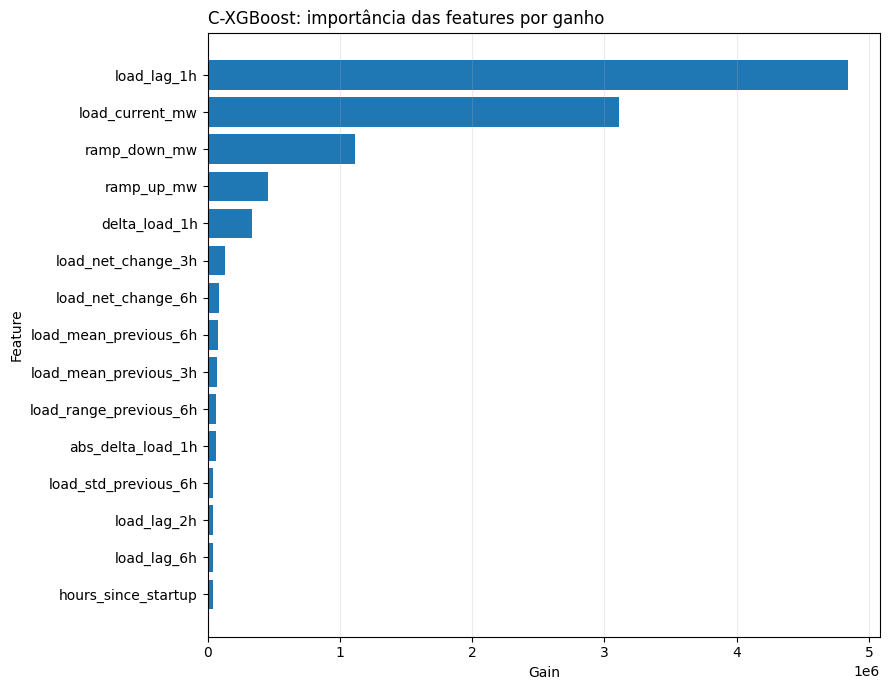

In [20]:
# ============================================================
# CÉLULA 19: GRÁFICO DE IMPORTÂNCIA DAS FEATURES
# ============================================================
#
# Mostramos apenas as 15 features com maior ganho para manter
# a visualização legível.
# ============================================================


top_features = (

    feature_importance

    .head(15)

    .sort_values(
        "gain",
        ascending=True
    )

)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


ax.barh(

    top_features[
        "feature"
    ],

    top_features[
        "gain"
    ]

)


ax.set_title(
    "C-XGBoost: importância das features por ganho",
    loc="left"
)


ax.set_xlabel(
    "Gain"
)


ax.set_ylabel(
    "Feature"
)


ax.grid(
    axis="x",
    alpha=0.25
)


fig.tight_layout()


IMPORTANCE_FIGURE_PATH = (

    FIGURES

    /

    "03A02_feature_importance_C_XGBoost.png"

)


fig.savefig(

    IMPORTANCE_FIGURE_PATH,

    dpi=220,

    bbox_inches="tight"

)


plt.show()

In [21]:
# ============================================================
# CÉLULA 20: PERSISTÊNCIA DOS RESULTADOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Salvar resultados da validação temporal, comparação final,
# análise por contexto, importância das features, previsões e
# modelos XGBoost.
# ============================================================


CV_RESULTS_PATH = (
    TABLES
    /
    "03A02_cv_xgboost.csv"
)


CV_SUMMARY_PATH = (
    TABLES
    /
    "03A02_cv_summary_xgboost.csv"
)


MODEL_COMPARISON_PATH = (
    TABLES
    /
    "03A02_comparacao_modelos.csv"
)


CONTEXT_PATH = (
    TABLES
    /
    "03A02_comparacao_contextos_xgboost.csv"
)


IMPORTANCE_PATH = (
    TABLES
    /
    "03A02_feature_importance_C.csv"
)


# ============================================================
# 1. PREVISÕES
# ============================================================

predictions_xgb = pd.DataFrame({

    "timestamp":

        test_data[
            "timestamp"
        ]
        .to_numpy(),

    "co2_observed":

        y_test_true,

    "pred_B_XGBoost":

        pred_B_xgb,

    "pred_C_XGBoost":

        pred_C_xgb,

    "residual_B_XGBoost":

        residual_B_xgb,

    "residual_C_XGBoost":

        residual_C_xgb

})


PREDICTIONS_PATH = (
    TABLES
    /
    "03A02_previsoes_xgboost.csv"
)


# ============================================================
# 2. SALVAR TABELAS
# ============================================================

cv_results.to_csv(
    CV_RESULTS_PATH,
    index=False
)


cv_summary.to_csv(
    CV_SUMMARY_PATH,
    index=False
)


model_comparison.to_csv(
    MODEL_COMPARISON_PATH,
    index=False
)


xgb_context_results.to_csv(
    CONTEXT_PATH,
    index=False
)


feature_importance.to_csv(
    IMPORTANCE_PATH,
    index=False
)


predictions_xgb.to_csv(
    PREDICTIONS_PATH,
    index=False
)


# ============================================================
# 3. SALVAR MODELOS
# ============================================================
#
# Formato JSON é nativo e portátil para modelos XGBoost.
# ============================================================

final_models[
    "B-XGBoost"
].save_model(

    MODELS
    /
    "03A02_xgboost_B.json"

)


final_models[
    "C-XGBoost"
].save_model(

    MODELS
    /
    "03A02_xgboost_C.json"

)


print(
    "Artefatos do Notebook 3A.02 salvos."
)

Artefatos do Notebook 3A.02 salvos.


In [22]:
# ============================================================
# CÉLULA 21: RELATÓRIO E DIAGNÓSTICO FINAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Consolidar todos os resultados obtidos no Notebook 3A.02,
# incluindo os sanity checks realizados após a primeira
# comparação MLP x XGBoost.
#
#
# O relatório final passa a responder cinco perguntas:
#
#   1. As features foram construídas corretamente?
#
#   2. Existe evidência de target leakage ou vazamento temporal?
#
#   3. O ganho do XGBoost é consequência de uma base diferente?
#
#   4. A trajetória operacional realmente melhora o XGBoost
#      em relação ao uso somente da carga instantânea?
#
#   5. Qual deve ser o próximo experimento?
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Depois do sanity check, o Cenário A também foi avaliado com
# XGBoost.
#
# Isso permite separar:
#
#       efeito da família de modelo
#
# de:
#
#       efeito das informações de trajetória.
# ============================================================


# ============================================================
# 1. RECUPERAR RESULTADOS A, B E C DA VALIDAÇÃO TEMPORAL
# ============================================================

cv_A_final = (

    cv_ABC_summary[

        cv_ABC_summary[
            "cenario"
        ]
        ==
        "A"

    ]

    .iloc[0]

)


cv_B_final = (

    cv_ABC_summary[

        cv_ABC_summary[
            "cenario"
        ]
        ==
        "B"

    ]

    .iloc[0]

)


cv_C_final = (

    cv_ABC_summary[

        cv_ABC_summary[
            "cenario"
        ]
        ==
        "C"

    ]

    .iloc[0]

)


# ============================================================
# 2. RECUPERAR RESULTADOS A, B E C NO HOLDOUT HISTÓRICO
# ============================================================

holdout_A = (

    xgb_ABC_holdout[

        xgb_ABC_holdout[
            "cenario"
        ]
        ==
        "A-XGBoost"

    ]

    .iloc[0]

)


holdout_B = (

    xgb_ABC_holdout[

        xgb_ABC_holdout[
            "cenario"
        ]
        ==
        "B-XGBoost"

    ]

    .iloc[0]

)


holdout_C = (

    xgb_ABC_holdout[

        xgb_ABC_holdout[
            "cenario"
        ]
        ==
        "C-XGBoost"

    ]

    .iloc[0]

)


# ============================================================
# 3. RECUPERAR RESULTADOS DAS MLPs
# ============================================================
#
# O arquivo do Notebook 3A.01 contém os resultados históricos
# dos Cenários A, B e C com MLP.
#
# Eles serão usados para separar o efeito:
#
#       MLP -> XGBoost
#
# mantendo o mesmo conjunto de features.
# ============================================================

mlp_A_final = (

    results_03A01[

        results_03A01[
            "cenario"
        ]
        .str.startswith("A")

    ]

    .iloc[0]

)


mlp_B_final = (

    results_03A01[

        results_03A01[
            "cenario"
        ]
        .str.startswith("B")

    ]

    .iloc[0]

)


mlp_C_final = (

    results_03A01[

        results_03A01[
            "cenario"
        ]
        .str.startswith("C")

    ]

    .iloc[0]

)


# ============================================================
# 4. QUANTIFICAR O EFEITO DA FAMÍLIA DE MODELO
# ============================================================
#
# Aqui comparamos, dentro de cada cenário:
#
#       MLP x XGBoost
#
# mantendo o mesmo conjunto de features.
#
# Isso permite avaliar quanto do ganho veio da troca do
# algoritmo, e não da engenharia de atributos.
# ============================================================


family_gain_A = (

    100

    *

    (
        mlp_A_final[
            "MAE"
        ]

        -

        holdout_A[
            "MAE"
        ]
    )

    /

    mlp_A_final[
        "MAE"
    ]

)


family_gain_B = (

    100

    *

    (
        mlp_B_final[
            "MAE"
        ]

        -

        holdout_B[
            "MAE"
        ]
    )

    /

    mlp_B_final[
        "MAE"
    ]

)


family_gain_C = (

    100

    *

    (
        mlp_C_final[
            "MAE"
        ]

        -

        holdout_C[
            "MAE"
        ]
    )

    /

    mlp_C_final[
        "MAE"
    ]

)


# ============================================================
# 5. QUANTIFICAR O EFEITO DA TRAJETÓRIA NO XGBOOST
# ============================================================
#
# Agora mantemos a mesma família de modelo e alteramos apenas
# as informações fornecidas.
#
#
# A:
# apenas carga instantânea.
#
# B:
# carga + trajetória básica.
#
# C:
# trajetória enriquecida.
# ============================================================


# ------------------------------------------------------------
# A -> B na validação temporal
# ------------------------------------------------------------

gain_A_to_B_cv = (

    100

    *

    (
        cv_A_final[
            "MAE_mean"
        ]

        -

        cv_B_final[
            "MAE_mean"
        ]
    )

    /

    cv_A_final[
        "MAE_mean"
    ]

)


# ------------------------------------------------------------
# A -> C na validação temporal
# ------------------------------------------------------------

gain_A_to_C_cv = (

    100

    *

    (
        cv_A_final[
            "MAE_mean"
        ]

        -

        cv_C_final[
            "MAE_mean"
        ]
    )

    /

    cv_A_final[
        "MAE_mean"
    ]

)


# ------------------------------------------------------------
# A -> B no holdout histórico
# ------------------------------------------------------------

gain_A_to_B_holdout = (

    100

    *

    (
        holdout_A[
            "MAE"
        ]

        -

        holdout_B[
            "MAE"
        ]
    )

    /

    holdout_A[
        "MAE"
    ]

)


# ------------------------------------------------------------
# A -> C no holdout histórico
# ------------------------------------------------------------

gain_A_to_C_holdout = (

    100

    *

    (
        holdout_A[
            "MAE"
        ]

        -

        holdout_C[
            "MAE"
        ]
    )

    /

    holdout_A[
        "MAE"
    ]

)


# ============================================================
# 6. RESULTADOS DOS SANITY CHECKS
# ============================================================


# ------------------------------------------------------------
# Features reconstruídas corretamente?
# ------------------------------------------------------------

features_ok = bool(

    feature_check_table[
        "status"
    ]

    .eq(
        "OK"
    )

    .all()

)


# ------------------------------------------------------------
# Alguma feature possui referência explícita ao CO₂?
# ------------------------------------------------------------

target_leakage_ok = (

    len(
        target_like_features
    )

    ==

    0

)


# ------------------------------------------------------------
# Classificação high_ramp consistente?
# ------------------------------------------------------------

high_ramp_ok = bool(

    high_ramp_check_table[
        "status"
    ]

    .eq(
        "OK"
    )

    .all()

)


# ------------------------------------------------------------
# Ordem temporal dos folds correta?
# ------------------------------------------------------------

fold_order_ok = bool(

    fold_integrity[
        "ordem_temporal_ok"
    ]

    .all()

)


# ------------------------------------------------------------
# Existe sobreposição entre treino e validação nos folds?
# ------------------------------------------------------------

fold_overlap_ok = bool(

    fold_integrity[
        "timestamps_sobrepostos"
    ]

    .eq(
        0
    )

    .all()

)


# ------------------------------------------------------------
# Existe sobreposição entre treino, validação e holdout final?
# ------------------------------------------------------------

final_split_overlap_ok = bool(

    final_split_table[
        "timestamps_sobrepostos"
    ]

    .eq(
        0
    )

    .all()

)


# ------------------------------------------------------------
# Número de observações do holdout
# ------------------------------------------------------------

n_holdout_current = int(
    len(
        test_data
    )
)


n_holdout_previous = int(
    len(
        previous_predictions
    )
)


# ------------------------------------------------------------
# Número de timestamps perfeitamente alinhados
# ------------------------------------------------------------

n_aligned = int(
    len(
        holdout_alignment
    )
)


# ------------------------------------------------------------
# Diferença máxima entre os valores observados de CO₂
# ------------------------------------------------------------

max_observed_difference = float(
    max_co2_difference
)


# ============================================================
# 7. SANITY CHECK GLOBAL
# ============================================================

sanity_check_ok = (

    features_ok

    and

    target_leakage_ok

    and

    high_ramp_ok

    and

    fold_order_ok

    and

    fold_overlap_ok

    and

    final_split_overlap_ok

    and

    (
        n_holdout_current
        ==
        n_holdout_previous
        ==
        n_aligned
    )

    and

    np.isclose(
        max_observed_difference,
        0.0,
        atol=1e-10
    )

)


# ============================================================
# 8. MELHOR CENÁRIO NA VALIDAÇÃO TEMPORAL
# ============================================================

best_cv_row = (

    cv_ABC_summary

    .sort_values(
        "MAE_mean"
    )

    .iloc[0]

)


best_cv_scenario = (

    best_cv_row[
        "cenario"
    ]

)


# ============================================================
# 9. MELHOR CENÁRIO NO HOLDOUT HISTÓRICO
# ============================================================

best_holdout_row = (

    xgb_ABC_holdout

    .sort_values(
        "MAE"
    )

    .iloc[0]

)


best_holdout_scenario = (

    best_holdout_row[
        "cenario"
    ]

)


# ============================================================
# 10. DIAGNÓSTICO DA FAMÍLIA DE MODELO
# ============================================================
#
# O sanity check mostrou que A-XGBoost, mesmo com apenas uma
# feature, apresenta desempenho muito superior às MLPs.
#
# Portanto, o maior ganho observado decorre da troca da família
# de modelo.
# ============================================================

family_diagnosis = f"""
A principal mudança de desempenho observada nesta sequência de
experimentos está associada à substituição da MLP pelo XGBoost.

Mantendo os mesmos conjuntos de informações, a redução de MAE
no holdout histórico foi:

- Cenário A: **{family_gain_A:+.2f}%**
- Cenário B: **{family_gain_B:+.2f}%**
- Cenário C: **{family_gain_C:+.2f}%**

O fato de o Cenário A, utilizando apenas carga instantânea,
também apresentar forte melhora demonstra que o ganho do
Gradient Boosting não pode ser atribuído principalmente às
features de trajetória.

Os resultados indicam que a família de modelo possui papel
determinante na capacidade de representar a relação entre carga
operacional e massa horária de CO₂.
"""


# ============================================================
# 11. DIAGNÓSTICO DAS FEATURES DE TRAJETÓRIA
# ============================================================

trajectory_diagnosis = f"""
Quando a família de modelo é mantida fixa no XGBoost, o ganho
incremental das informações de trajetória é pequeno.

Na validação temporal progressiva:

- A -> B: **{gain_A_to_B_cv:+.2f}%** de redução de MAE;
- A -> C: **{gain_A_to_C_cv:+.2f}%** de redução de MAE.

No holdout histórico:

- A -> B: **{gain_A_to_B_holdout:+.2f}%**;
- A -> C: **{gain_A_to_C_holdout:+.2f}%**.

Assim, a trajetória apresentou pequeno benefício médio durante
a validação temporal, mas esse ganho não se reproduziu no
holdout histórico.

Neste estágio, não há evidência suficientemente robusta para
afirmar que as variáveis adicionais de trajetória superam de
forma consistente o uso exclusivo da carga instantânea quando
o algoritmo utilizado é o XGBoost.
"""


# ============================================================
# 12. DIAGNÓSTICO DE PARCIMÔNIA
# ============================================================

parsimony_diagnosis = f"""
O Cenário A utiliza apenas **1 feature**, enquanto:

- B utiliza **7 features**;
- C utiliza **24 features**.

Apesar da diferença de complexidade, os três cenários
apresentaram resultados muito próximos na validação temporal.

Além disso, o melhor MAE observado no holdout histórico foi
obtido por:

**{best_holdout_scenario}**

Dessa forma, a inclusão de features adicionais somente deverá
ser mantida no modelo final se uma comparação após otimização
mostrar benefício consistente e reproduzível.
"""


# ============================================================
# 13. DIAGNÓSTICO DO SANITY CHECK
# ============================================================

if sanity_check_ok:

    sanity_diagnosis = f"""
Todos os controles metodológicos executados foram aprovados.

Foram verificadas:

- **{len(feature_check_table)} features reconstruídas**, todas
  com diferença máxima igual a zero em relação às definições
  esperadas;
- ausência de features derivadas de CO₂;
- cálculo de `high_ramp` utilizando exclusivamente o conjunto
  de treino;
- ordem temporal correta nos cinco folds;
- ausência de sobreposição entre treino e validação;
- ausência de sobreposição entre treino, validação e holdout;
- **{n_holdout_current} observações** no holdout atual;
- **{n_holdout_previous} observações** na avaliação anterior;
- **{n_aligned} timestamps** perfeitamente alinhados;
- diferença máxima de **{max_observed_difference:.10f}** entre
  os valores observados de CO₂ usados nas comparações.

Portanto, não foram identificados sinais de target leakage,
vazamento temporal ou diferença de base capaz de explicar a
melhora apresentada pelo XGBoost.
"""

else:

    sanity_diagnosis = """
Uma ou mais verificações do sanity check apresentaram falha.

Os resultados dos modelos não devem ser interpretados como
definitivos antes da investigação dessas inconsistências.
"""


# ============================================================
# 14. TABELA COMPLETA DAS FAMÍLIAS DE MODELO
# ============================================================

complete_model_comparison = pd.DataFrame([

    {
        "modelo":
            "A-MLP",

        "features":
            1,

        "MAE":
            mlp_A_final["MAE"],

        "RMSE":
            mlp_A_final["RMSE"],

        "R2":
            mlp_A_final["R2"]
    },

    {
        "modelo":
            "B-MLP",

        "features":
            7,

        "MAE":
            mlp_B_final["MAE"],

        "RMSE":
            mlp_B_final["RMSE"],

        "R2":
            mlp_B_final["R2"]
    },

    {
        "modelo":
            "C-MLP",

        "features":
            24,

        "MAE":
            mlp_C_final["MAE"],

        "RMSE":
            mlp_C_final["RMSE"],

        "R2":
            mlp_C_final["R2"]
    },

    {
        "modelo":
            "A-XGBoost",

        "features":
            1,

        "MAE":
            holdout_A["MAE"],

        "RMSE":
            holdout_A["RMSE"],

        "R2":
            holdout_A["R2"]
    },

    {
        "modelo":
            "B-XGBoost",

        "features":
            7,

        "MAE":
            holdout_B["MAE"],

        "RMSE":
            holdout_B["RMSE"],

        "R2":
            holdout_B["R2"]
    },

    {
        "modelo":
            "C-XGBoost",

        "features":
            24,

        "MAE":
            holdout_C["MAE"],

        "RMSE":
            holdout_C["RMSE"],

        "R2":
            holdout_C["R2"]
    }

])


# ============================================================
# 15. SALVAR TABELAS PRODUZIDAS PELO SANITY CHECK
# ============================================================

feature_check_table.to_csv(

    TABLES
    /
    "03A02_sanity_check_features.csv",

    index=False

)


fold_integrity.to_csv(

    TABLES
    /
    "03A02_sanity_check_folds.csv",

    index=False

)


alignment_summary.to_csv(

    TABLES
    /
    "03A02_sanity_check_holdout.csv",

    index=False

)


cv_ABC_summary.to_csv(

    TABLES
    /
    "03A02_cv_ABC_xgboost.csv",

    index=False

)


xgb_ABC_holdout.to_csv(

    TABLES
    /
    "03A02_holdout_ABC_xgboost.csv",

    index=False

)


complete_model_comparison.to_csv(

    TABLES
    /
    "03A02_comparacao_completa_modelos.csv",

    index=False

)


# ============================================================
# 16. CONSTRUIR RELATÓRIO FINAL
# ============================================================

report = f"""
# Relatório: Notebook 3A.02

## 1. Objetivo

Avaliar se modelos de Gradient Boosting conseguem explorar as
informações operacionais dos Cenários A, B e C de forma mais
eficiente que as MLPs utilizadas nos experimentos anteriores.

O notebook também investiga se a inclusão de informações de
trajetória operacional apresenta ganho preditivo além do uso
exclusivo da carga instantânea quando a família de modelo é
mantida fixa.

---

## 2. Cenários avaliados

### Cenário A

Carga instantânea:

`CO₂(t) = f(P(t))`

Número de features: **1**

### Cenário B

Carga instantânea + trajetória operacional básica.

Número de features: **7**

### Cenário C

Trajetória temporal enriquecida.

Número de features: **24**

---

## 3. Validação temporal progressiva

Foram utilizados cinco folds temporais:

1. janeiro a maio -> junho;
2. janeiro a junho -> julho;
3. janeiro a julho -> agosto;
4. janeiro a agosto -> setembro;
5. janeiro a setembro -> outubro.

### Resultados médios do XGBoost

| Cenário | MAE médio | Desvio MAE | RMSE médio | Desvio RMSE | R² médio | Desvio R² |
|---|---:|---:|---:|---:|---:|---:|
| A | {cv_A_final['MAE_mean']:.4f} | {cv_A_final['MAE_std']:.4f} | {cv_A_final['RMSE_mean']:.4f} | {cv_A_final['RMSE_std']:.4f} | {cv_A_final['R2_mean']:.4f} | {cv_A_final['R2_std']:.4f} |
| B | {cv_B_final['MAE_mean']:.4f} | {cv_B_final['MAE_std']:.4f} | {cv_B_final['RMSE_mean']:.4f} | {cv_B_final['RMSE_std']:.4f} | {cv_B_final['R2_mean']:.4f} | {cv_B_final['R2_std']:.4f} |
| C | {cv_C_final['MAE_mean']:.4f} | {cv_C_final['MAE_std']:.4f} | {cv_C_final['RMSE_mean']:.4f} | {cv_C_final['RMSE_std']:.4f} | {cv_C_final['R2_mean']:.4f} | {cv_C_final['R2_std']:.4f} |

O cenário com menor MAE médio na validação temporal foi:

**Cenário {best_cv_scenario}**

---

## 4. Ganho incremental das informações de trajetória

Mantendo o algoritmo XGBoost fixo:

### Validação temporal

- A -> B: **{gain_A_to_B_cv:+.2f}%**
- A -> C: **{gain_A_to_C_cv:+.2f}%**

### Holdout histórico

- A -> B: **{gain_A_to_B_holdout:+.2f}%**
- A -> C: **{gain_A_to_C_holdout:+.2f}%**

{trajectory_diagnosis}

---

## 5. Comparação no holdout histórico

O período de novembro e dezembro permanece como referência para
comparação com os notebooks anteriores.

Entretanto, esse período já foi observado durante o processo de
desenvolvimento e não deve ser tratado como teste completamente
cego para novas decisões metodológicas.

### Resultados

| Cenário | Features | MAE | RMSE | R² |
|---|---:|---:|---:|---:|
| A-XGBoost | 1 | {holdout_A['MAE']:.4f} | {holdout_A['RMSE']:.4f} | {holdout_A['R2']:.4f} |
| B-XGBoost | 7 | {holdout_B['MAE']:.4f} | {holdout_B['RMSE']:.4f} | {holdout_B['R2']:.4f} |
| C-XGBoost | 24 | {holdout_C['MAE']:.4f} | {holdout_C['RMSE']:.4f} | {holdout_C['R2']:.4f} |

O menor MAE neste período foi obtido por:

**{best_holdout_scenario}**

---

## 6. Comparação MLP x XGBoost

A comparação com os modelos anteriores mostra forte efeito da
família de algoritmo.

### Redução de MAE ao substituir MLP por XGBoost

- Cenário A: **{family_gain_A:+.2f}%**
- Cenário B: **{family_gain_B:+.2f}%**
- Cenário C: **{family_gain_C:+.2f}%**

{family_diagnosis}

---

## 7. Sanity check

Como o XGBoost apresentou melhora muito expressiva em relação às
MLPs, foram realizados controles adicionais antes de interpretar
esse resultado.

{sanity_diagnosis}

---

## 8. Validade da comparação temporal

Todos os cinco folds apresentaram:

- treino anterior à validação;
- ausência de sobreposição de timestamps.

No split final também não houve sobreposição entre:

- treino e validação;
- treino e holdout;
- validação e holdout.

Além disso, MLP e XGBoost foram avaliados sobre exatamente as
mesmas **{n_holdout_current} observações** no holdout histórico.

---

## 9. Parcimônia do modelo

{parsimony_diagnosis}

---

## 10. Diagnóstico final

Os experimentos realizados até este ponto permitem separar dois
efeitos.

### Efeito da família de modelo

A mudança de MLP para XGBoost produziu uma redução muito
expressiva do erro, inclusive quando apenas a carga instantânea
foi utilizada.

Portanto, o principal ganho observado decorre da capacidade do
Gradient Boosting de representar a relação não linear entre as
variáveis operacionais e a massa horária de CO₂.

### Efeito da trajetória operacional

Quando a família XGBoost é mantida fixa, os Cenários B e C
apresentam apenas pequeno ganho médio na validação temporal em
relação ao Cenário A.

Esse ganho não se reproduz no holdout histórico.

Assim, neste estágio, ainda não existe evidência robusta de que
a trajetória operacional melhore consistentemente o XGBoost em
relação ao uso exclusivo da carga instantânea.

---

## 11. Implicação para o próximo experimento

O resultado do sanity check modifica a estratégia inicialmente
planejada para o Notebook 3A.03.

Não é metodologicamente adequado otimizar apenas o Cenário B.

A próxima etapa deverá realizar uma **otimização pareada** de:

### A-XGBoost

- 1 feature;
- apenas carga instantânea.

### B-XGBoost

- 7 features;
- carga + trajetória operacional básica.

Os dois cenários deverão utilizar:

- o mesmo espaço de hiperparâmetros;
- a mesma estratégia de busca;
- os mesmos cinco folds temporais;
- MAE médio da validação temporal como métrica primária de
  seleção.

O Cenário C não será priorizado nesta etapa, pois o aumento de 7
para 24 features produziu apenas pequeno ganho médio na validação
temporal e pior desempenho no holdout histórico.

---

## 12. Pergunta para o Notebook 3A.03

A próxima etapa responderá:

> **Após otimização controlada da mesma família de modelo, a inclusão de informações de trajetória operacional oferece ganho preditivo consistente em relação ao uso exclusivo da carga instantânea?**

Essa comparação permitirá avaliar o valor incremental das
informações de trajetória sem confundir esse efeito com diferenças
de arquitetura ou de grau de otimização dos modelos.

---

## 13. Fundamentação metodológica dos modelos e da validação temporal

### 13.1. Aprendizado supervisionado para regressão e GBRT

O problema consiste em estimar a massa horária de CO₂, uma variável-alvo contínua, a partir das características operacionais disponíveis. Portanto, a tarefa é de **aprendizado supervisionado para regressão** (*supervised regression*).

O XGBoost (*Extreme Gradient Boosting*) é utilizado como implementação de **gradient-boosted regression trees (GBRT)**. Não é uma árvore de decisão isolada: trata-se de um **ensemble sequencial de árvores de regressão**, cujas contribuições são combinadas em uma única predição. A função objetivo `reg:squarederror` orienta o ajuste para erro quadrático; profundidade, taxa de aprendizado, amostragem e regularização limitam a complexidade do modelo.

### 13.2. Validação walk-forward com janela expansiva

Os cinco folds constituem uma **walk-forward validation with an expanding training window** (*expanding-window time-series cross-validation*). A janela de treinamento aumenta ao longo dos meses e cada validação recai sobre o mês seguinte, preservando a ordem temporal. Isso é diferente de um *K-fold* aleatório, que pode misturar passado e futuro.

O conjunto de validação de cada fold também é utilizado pelo **early stopping** para definir a complexidade efetiva do ensemble. Consequentemente, os resultados da validação temporal caracterizam o desempenho durante o desenvolvimento, sem representar um teste independente completamente cego. Novembro e dezembro permanecem como **holdout temporal histórico de comparação**, visto que já foram examinados nos experimentos anteriores.

### 13.3. Early stopping e configuração de referência

A configuração do XGBoost foi mantida fixa nesta etapa, sem *random search* ou outra busca de hiperparâmetros. O **early stopping** acompanha o RMSE de validação e interrompe o treinamento quando novas árvores deixam de proporcionar melhora conforme o critério especificado. Dessa maneira, o número efetivo de árvores é condicionado ao período de validação de cada ajuste, mantendo os demais parâmetros de referência.

### 13.4. Comparações controladas de algoritmos e variáveis

A comparação entre MLP e XGBoost utiliza, dentro de cada cenário, o mesmo conjunto de variáveis de entrada. A comparação dos Cenários A, B e C, por sua vez, mantém o XGBoost como família de modelo, alterando a representação da operação. Esse desenho ajuda a distinguir **efeito da família de algoritmo** e **valor incremental das variáveis de trajetória**, sem atribuir causalidade à diferença observada nas métricas.

### 13.5. Importância por ganho das variáveis

A importância das *features* é calculada pelo critério **gain** (`importance_type="gain"`), correspondente à melhoria média da função objetivo nas divisões que empregam cada variável. Essa medida descreve a utilização das variáveis pelas árvores treinadas, mas **não** identifica efeitos causais e **não** equivale a uma análise SHAP.
"""


# ============================================================
# 17. EXIBIR RELATÓRIO
# ============================================================

display(
    Markdown(
        report
    )
)


# ============================================================
# 18. SALVAR RELATÓRIO
# ============================================================

REPORT_PATH = (

    REPORTS

    /

    "relatorio_modelagem_preditiva_03A02.md"

)


with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    f.write(
        report
    )


# ============================================================
# 19. CONFIRMAÇÃO
# ============================================================

print(
    "\nRelatório atualizado salvo em:"
)

print(
    REPORT_PATH
)


print(
    "\nSanity check global:",
    "APROVADO"
    if sanity_check_ok
    else "REPROVADO"
)


print(
    "\nPróximo experimento:"
)

print(
    "03A.03: otimização pareada de A-XGBoost e B-XGBoost."
)


# Relatório: Notebook 3A.02

## 1. Objetivo

Avaliar se modelos de Gradient Boosting conseguem explorar as
informações operacionais dos Cenários A, B e C de forma mais
eficiente que as MLPs utilizadas nos experimentos anteriores.

O notebook também investiga se a inclusão de informações de
trajetória operacional apresenta ganho preditivo além do uso
exclusivo da carga instantânea quando a família de modelo é
mantida fixa.

---

## 2. Cenários avaliados

### Cenário A

Carga instantânea:

`CO₂(t) = f(P(t))`

Número de features: **1**

### Cenário B

Carga instantânea + trajetória operacional básica.

Número de features: **7**

### Cenário C

Trajetória temporal enriquecida.

Número de features: **24**

---

## 3. Validação temporal progressiva

Foram utilizados cinco folds temporais:

1. janeiro a maio -> junho;
2. janeiro a junho -> julho;
3. janeiro a julho -> agosto;
4. janeiro a agosto -> setembro;
5. janeiro a setembro -> outubro.

### Resultados médios do XGBoost

| Cenário | MAE médio | Desvio MAE | RMSE médio | Desvio RMSE | R² médio | Desvio R² |
|---|---:|---:|---:|---:|---:|---:|
| A | 56.6132 | 17.3006 | 72.1941 | 14.9393 | 0.8582 | 0.0623 |
| B | 56.2298 | 17.0684 | 71.8576 | 14.0435 | 0.8591 | 0.0606 |
| C | 55.6889 | 17.2915 | 71.0960 | 14.3441 | 0.8623 | 0.0598 |

O cenário com menor MAE médio na validação temporal foi:

**Cenário C**

---

## 4. Ganho incremental das informações de trajetória

Mantendo o algoritmo XGBoost fixo:

### Validação temporal

- A -> B: **+0.68%**
- A -> C: **+1.63%**

### Holdout histórico

- A -> B: **-1.32%**
- A -> C: **-8.96%**


Quando a família de modelo é mantida fixa no XGBoost, o ganho
incremental das informações de trajetória é pequeno.

Na validação temporal progressiva:

- A -> B: **+0.68%** de redução de MAE;
- A -> C: **+1.63%** de redução de MAE.

No holdout histórico:

- A -> B: **-1.32%**;
- A -> C: **-8.96%**.

Assim, a trajetória apresentou pequeno benefício médio durante
a validação temporal, mas esse ganho não se reproduziu no
holdout histórico.

Neste estágio, não há evidência suficientemente robusta para
afirmar que as variáveis adicionais de trajetória superam de
forma consistente o uso exclusivo da carga instantânea quando
o algoritmo utilizado é o XGBoost.


---

## 5. Comparação no holdout histórico

O período de novembro e dezembro permanece como referência para
comparação com os notebooks anteriores.

Entretanto, esse período já foi observado durante o processo de
desenvolvimento e não deve ser tratado como teste completamente
cego para novas decisões metodológicas.

### Resultados

| Cenário | Features | MAE | RMSE | R² |
|---|---:|---:|---:|---:|
| A-XGBoost | 1 | 22.9625 | 28.0571 | 0.9809 |
| B-XGBoost | 7 | 23.2657 | 28.8090 | 0.9798 |
| C-XGBoost | 24 | 25.0194 | 30.6338 | 0.9772 |

O menor MAE neste período foi obtido por:

**A-XGBoost**

---

## 6. Comparação MLP x XGBoost

A comparação com os modelos anteriores mostra forte efeito da
família de algoritmo.

### Redução de MAE ao substituir MLP por XGBoost

- Cenário A: **+65.86%**
- Cenário B: **+62.24%**
- Cenário C: **+60.06%**


A principal mudança de desempenho observada nesta sequência de
experimentos está associada à substituição da MLP pelo XGBoost.

Mantendo os mesmos conjuntos de informações, a redução de MAE
no holdout histórico foi:

- Cenário A: **+65.86%**
- Cenário B: **+62.24%**
- Cenário C: **+60.06%**

O fato de o Cenário A, utilizando apenas carga instantânea,
também apresentar forte melhora demonstra que o ganho do
Gradient Boosting não pode ser atribuído principalmente às
features de trajetória.

Os resultados indicam que a família de modelo possui papel
determinante na capacidade de representar a relação entre carga
operacional e massa horária de CO₂.


---

## 7. Sanity check

Como o XGBoost apresentou melhora muito expressiva em relação às
MLPs, foram realizados controles adicionais antes de interpretar
esse resultado.


Todos os controles metodológicos executados foram aprovados.

Foram verificadas:

- **23 features reconstruídas**, todas
  com diferença máxima igual a zero em relação às definições
  esperadas;
- ausência de features derivadas de CO₂;
- cálculo de `high_ramp` utilizando exclusivamente o conjunto
  de treino;
- ordem temporal correta nos cinco folds;
- ausência de sobreposição entre treino e validação;
- ausência de sobreposição entre treino, validação e holdout;
- **1144 observações** no holdout atual;
- **1144 observações** na avaliação anterior;
- **1144 timestamps** perfeitamente alinhados;
- diferença máxima de **0.0000000000** entre
  os valores observados de CO₂ usados nas comparações.

Portanto, não foram identificados sinais de target leakage,
vazamento temporal ou diferença de base capaz de explicar a
melhora apresentada pelo XGBoost.


---

## 8. Validade da comparação temporal

Todos os cinco folds apresentaram:

- treino anterior à validação;
- ausência de sobreposição de timestamps.

No split final também não houve sobreposição entre:

- treino e validação;
- treino e holdout;
- validação e holdout.

Além disso, MLP e XGBoost foram avaliados sobre exatamente as
mesmas **1144 observações** no holdout histórico.

---

## 9. Parcimônia do modelo


O Cenário A utiliza apenas **1 feature**, enquanto:

- B utiliza **7 features**;
- C utiliza **24 features**.

Apesar da diferença de complexidade, os três cenários
apresentaram resultados muito próximos na validação temporal.

Além disso, o melhor MAE observado no holdout histórico foi
obtido por:

**A-XGBoost**

Dessa forma, a inclusão de features adicionais somente deverá
ser mantida no modelo final se uma comparação após otimização
mostrar benefício consistente e reproduzível.


---

## 10. Diagnóstico final

Os experimentos realizados até este ponto permitem separar dois
efeitos.

### Efeito da família de modelo

A mudança de MLP para XGBoost produziu uma redução muito
expressiva do erro, inclusive quando apenas a carga instantânea
foi utilizada.

Portanto, o principal ganho observado decorre da capacidade do
Gradient Boosting de representar a relação não linear entre as
variáveis operacionais e a massa horária de CO₂.

### Efeito da trajetória operacional

Quando a família XGBoost é mantida fixa, os Cenários B e C
apresentam apenas pequeno ganho médio na validação temporal em
relação ao Cenário A.

Esse ganho não se reproduz no holdout histórico.

Assim, neste estágio, ainda não existe evidência robusta de que
a trajetória operacional melhore consistentemente o XGBoost em
relação ao uso exclusivo da carga instantânea.

---

## 11. Implicação para o próximo experimento

O resultado do sanity check modifica a estratégia inicialmente
planejada para o Notebook 3A.03.

Não é metodologicamente adequado otimizar apenas o Cenário B.

A próxima etapa deverá realizar uma **otimização pareada** de:

### A-XGBoost

- 1 feature;
- apenas carga instantânea.

### B-XGBoost

- 7 features;
- carga + trajetória operacional básica.

Os dois cenários deverão utilizar:

- o mesmo espaço de hiperparâmetros;
- a mesma estratégia de busca;
- os mesmos cinco folds temporais;
- MAE médio da validação temporal como métrica primária de
  seleção.

O Cenário C não será priorizado nesta etapa, pois o aumento de 7
para 24 features produziu apenas pequeno ganho médio na validação
temporal e pior desempenho no holdout histórico.

---

## 12. Pergunta para o Notebook 3A.03

A próxima etapa responderá:

> **Após otimização controlada da mesma família de modelo, a inclusão de informações de trajetória operacional oferece ganho preditivo consistente em relação ao uso exclusivo da carga instantânea?**

Essa comparação permitirá avaliar o valor incremental das
informações de trajetória sem confundir esse efeito com diferenças
de arquitetura ou de grau de otimização dos modelos.

---

## 13. Fundamentação metodológica dos modelos e da validação temporal

### 13.1. Aprendizado supervisionado para regressão e GBRT

O problema consiste em estimar a massa horária de CO₂, uma variável-alvo contínua, a partir das características operacionais disponíveis. Portanto, a tarefa é de **aprendizado supervisionado para regressão** (*supervised regression*).

O XGBoost (*Extreme Gradient Boosting*) é utilizado como implementação de **gradient-boosted regression trees (GBRT)**. Não é uma árvore de decisão isolada: trata-se de um **ensemble sequencial de árvores de regressão**, cujas contribuições são combinadas em uma única predição. A função objetivo `reg:squarederror` orienta o ajuste para erro quadrático; profundidade, taxa de aprendizado, amostragem e regularização limitam a complexidade do modelo.

### 13.2. Validação walk-forward com janela expansiva

Os cinco folds constituem uma **walk-forward validation with an expanding training window** (*expanding-window time-series cross-validation*). A janela de treinamento aumenta ao longo dos meses e cada validação recai sobre o mês seguinte, preservando a ordem temporal. Isso é diferente de um *K-fold* aleatório, que pode misturar passado e futuro.

O conjunto de validação de cada fold também é utilizado pelo **early stopping** para definir a complexidade efetiva do ensemble. Consequentemente, os resultados da validação temporal caracterizam o desempenho durante o desenvolvimento, sem representar um teste independente completamente cego. Novembro e dezembro permanecem como **holdout temporal histórico de comparação**, visto que já foram examinados nos experimentos anteriores.

### 13.3. Early stopping e configuração de referência

A configuração do XGBoost foi mantida fixa nesta etapa, sem *random search* ou outra busca de hiperparâmetros. O **early stopping** acompanha o RMSE de validação e interrompe o treinamento quando novas árvores deixam de proporcionar melhora conforme o critério especificado. Dessa maneira, o número efetivo de árvores é condicionado ao período de validação de cada ajuste, mantendo os demais parâmetros de referência.

### 13.4. Comparações controladas de algoritmos e variáveis

A comparação entre MLP e XGBoost utiliza, dentro de cada cenário, o mesmo conjunto de variáveis de entrada. A comparação dos Cenários A, B e C, por sua vez, mantém o XGBoost como família de modelo, alterando a representação da operação. Esse desenho ajuda a distinguir **efeito da família de algoritmo** e **valor incremental das variáveis de trajetória**, sem atribuir causalidade à diferença observada nas métricas.

### 13.5. Importância por ganho das variáveis

A importância das *features* é calculada pelo critério **gain** (`importance_type="gain"`), correspondente à melhoria média da função objetivo nas divisões que empregam cada variável. Essa medida descreve a utilização das variáveis pelas árvores treinadas, mas **não** identifica efeitos causais e **não** equivale a uma análise SHAP.



Relatório atualizado salvo em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/reports/relatorio_modelagem_preditiva_03A02.md

Sanity check global: APROVADO

Próximo experimento:
03A.03: otimização pareada de A-XGBoost e B-XGBoost.


## Referências

CAWLEY, G. C.; TALBOT, N. L. C. On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation. **Journal of Machine Learning Research**, *[s. l.]*, v. 11, n. 70, p. 2079-2107, 2010. Disponível em: https://jmlr.org/papers/v11/cawley10a.html. Acesso em: 24 out. 2026.

CERQUEIRA, V.; TORGO, L.; MOZETIČ, I. Evaluating time series forecasting models: an empirical study on performance estimation methods. **Machine Learning**, *[s. l.]*, v. 109, n. 11, p. 1997-2028, 2020. DOI: https://doi.org/10.1007/s10994-020-05910-7. Disponível em: https://link.springer.com/article/10.1007/s10994-020-05910-7. Acesso em: 24 out. 2026.

CHEN, T.; GUESTRIN, C. XGBoost: A Scalable Tree Boosting System. *In:* ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY AND DATA MINING, 22., 2016, San Francisco. **Proceedings [...]**. New York: ACM, 2016. p. 785-794. DOI: https://doi.org/10.1145/2939672.2939785. Disponível em: https://www.kdd.org/kdd2016/papers/files/rfp0697-chenAemb.pdf. Acesso em: 24 out. 2026.

FRIEDMAN, J. H. Greedy function approximation: A gradient boosting machine. **The Annals of Statistics**, *[s. l.]*, v. 29, n. 5, p. 1189-1232, 2001. DOI: https://doi.org/10.1214/aos/1013203451. Disponível em: https://projecteuclid.org/journals/annals-of-statistics/volume-29/issue-5/Greedy-function-approximation-A-gradient-boosting-machine/10.1214/aos/1013203451.full. Acesso em: 24 out. 2026.

HYNDMAN, R. J.; KOEHLER, A. B. Another look at measures of forecast accuracy. **International Journal of Forecasting**, *[s. l.]*, v. 22, n. 4, p. 679-688, 2006. DOI: https://doi.org/10.1016/j.ijforecast.2006.03.001. Disponível em: https://robjhyndman.com/publications/another-look-at-measures-of-forecast-accuracy/. Acesso em: 24 out. 2026.

RUMELHART, D. E.; HINTON, G. E.; WILLIAMS, R. J. Learning representations by back-propagating errors. **Nature**, *[s. l.]*, v. 323, n. 6088, p. 533-536, 1986. DOI: https://doi.org/10.1038/323533a0. Disponível em: https://www.cs.toronto.edu/~hinton/absps/naturebp.pdf. Acesso em: 24 out. 2026.

SCIKIT-LEARN. **User Guide**. Version 1.8.0. *[S. l.]*: The scikit-learn developers, [2025]. Disponível em: https://scikit-learn.org/1.8/user_guide.html. Acesso em: 24 out. 2026.
